# Notebook Lengkap Eksperimen INDOMEME

**Kelompok 7 — Joseph Pratama Lase dan Rafa Maritza Hanasaputri**
## Kelompok 7 dan Joseph Lase
Pengumpulan 30 Oktober 2026. Bukti utama berasal dari eksperimen 18–29 Oktober 2026.

**Jika meme menggabungkan gambar dan teks, apakah menambahkan gambar selalu membantu model?**
Meme dapat menyampaikan kebencian atau ketidaklayakan melalui hubungan visual, teks, dan konteksnya.
Notebook ini mengikuti pertanyaan tersebut dari audit data sampai hasil terukur, termasuk hasil yang
tidak membaik dan percobaan yang tidak selesai.

Paket inti mencakup **8 konfigurasi supervised dan 10 hasil tugas**. Riwayat proyek juga menyimpan
14 baseline konvensional pada validation, hasil SwinV2 historis di luar paket inti, kalibrasi,
serta kegagalan yang dipisahkan dari eksperimen selesai. RQ3/API dan novelty tidak dinyatakan selesai.

**Mode eksekusi notebook:** membaca artefak yang dibekukan, menghitung ulang metrik, dan menggambar
visualisasi. Tidak ada training ulang, inferensi model, pemanggilan API, atau unduhan dataset/bobot.
Kode implementasi tetap diperlihatkan agar alur data, model, loss, dan pelatihan dapat dijelaskan.
Sel terakhir mencatat host dan waktu eksekusi aktual. Tidak ada keluaran yang diisi secara manual.

In [1]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import ast, hashlib, json, platform, socket, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

ROOT=next((p.resolve() for p in [Path.cwd(),Path.cwd().parent]
           if (p/'results/core_results.csv').is_file() and (p/'evidence/research_facts.json').is_file()),None)
assert ROOT is not None, 'Jalankan notebook dari root paket atau satu subfolder di dalamnya.'
pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)
plt.rcParams.update({'figure.dpi':115,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
CHECKS={'training_or_inference_started':False,'core_test_outcomes':0,'baseline_validation_trials':0}

def path(relative):
    candidate=(ROOT/relative).resolve()
    assert candidate.is_relative_to(ROOT), 'Path keluar dari paket.'
    return candidate

def read_json(relative):
    return json.loads(path(relative).read_text(encoding='utf-8-sig'))

def read_csv(relative):
    return pd.read_csv(path(relative),keep_default_na=False)

def sha256(file):
    with Path(file).open('rb') as stream:
        return hashlib.file_digest(stream,'sha256').hexdigest()

facts=read_json('evidence/research_facts.json')
inventory=read_json('evidence/inventory.json')
audit=read_json('evidence/local_results_audit.json')
core=read_csv('results/core_results.csv')
assert audit['passed'] and len(core)==10 and core.id.nunique()==8
print('Root paket:',ROOT)
print('Python:',platform.python_version(),'pandas:',pd.__version__,'numpy:',np.__version__)
print('Mode: analisis artefak tersimpan, tanpa training atau inferensi baru.')

Root paket: /mnt/home/probation-03/kelompok-7/notebooks/full-2026-10-30-f295774de3/notebook-lengkap
Python: 3.12.3 pandas: 2.3.3 numpy: 2.5.4
Mode: analisis artefak tersimpan, tanpa training atau inferensi baru.


## Pertanyaan riset dan cara membaca bukti
RQ1 pada paket ini adalah audit data rilis, bukan pengulangan pengumpulan dan anotasi.
RQ2 membandingkan ViT, IndoBERTweet, dan fusi keduanya. RQ4 membandingkan single-task dengan
dua model multitask terpilih. RQ3 dibahas sebagai referensi paper dan riwayat percobaan,
bukan hasil zero-shot yang berhasil diselesaikan.

Setiap bagian memisahkan **hasil teramati**, **interpretasi sementara**, dan **batas klaim**.
Model dilatih pada fit, checkpoint dipilih dari validation, lalu protokol dikunci sebelum test.
Skor test tidak menjadi alasan menambah seed, mengubah lambda, atau mencari konfigurasi baru.

In [2]:
display(pd.DataFrame([
 {'Bagian':'RQ1','Cakupan':'Audit data, label, topik, duplikat dan tokenisasi','Status':'Bukti tersimpan'},
 {'Bagian':'RQ2','Cakupan':'Gambar, teks, fusi pada ViT/IndoBERTweet','Status':'6 konfigurasi inti selesai'},
 {'Bagian':'RQ4','Cakupan':'Multitask teks dan fusi','Status':'2 konfigurasi inti selesai'},
 {'Bagian':'RQ3','Cakupan':'Zero-shot/API','Status':'Di luar target aktif, tidak ada hasil lengkap'},
]))
records=[]
for file in inventory.get('staged_files',[]):
    p=path(file['relative_path'])
    assert p.is_file() and p.stat().st_size==file['bytes']
    assert sha256(p)==file['sha256'],file['relative_path']
    records.append({'Berkas':file['relative_path'],'Byte':file['bytes'],'SHA256 cocok':True})
assert records,'Manifest bukti tambahan kosong.'
CHECKS['additional_artifact_hashes']=len(records)
display(pd.DataFrame(records))
print('Seluruh bukti tambahan cocok checksum. Bobot model besar tidak diperlukan untuk notebook ini.')

,Bagian,Cakupan,Status
0,RQ1,"Audit data, label, topik, duplikat dan tokenisasi",Bukti tersimpan
1,RQ2,"Gambar, teks, fusi pada ViT/IndoBERTweet",6 konfigurasi inti selesai
2,RQ4,Multitask teks dan fusi,2 konfigurasi inti selesai
3,RQ3,Zero-shot/API,"Di luar target aktif, tidak ada hasil lengkap"


,Berkas,Byte,SHA256 cocok
0,evidence/baseline_validation_2026-10-18/config.json,2702,True
1,evidence/baseline_validation_2026-10-18/metrics.csv,1807,True
2,evidence/baseline_validation_2026-10-18/metrics.json,5950,True
3,evidence/baseline_validation_2026-10-18/predictions.csv,711968,True
4,evidence/baseline_validation_2026-10-18/split_manifest.csv,208662,True
...,...,...,...
56,evidence/data_audits/perceptual_audit.json,484,True
57,evidence/data_audits/perceptual_duplicate_candidates.csv,14140,True
58,evidence/data_audits/perceptual_hashes.csv,229868,True
59,evidence/data_audits/tokenizer_audit_all.csv,1076,True


Seluruh bukti tambahan cocok checksum. Bobot model besar tidak diperlukan untuk notebook ini.


## Data asal revisi dan lisensi
INDOMEME menggunakan 5.023 meme pada rilis yang dipatok. Materi tambahan penerbit diperiksa silang
dengan rilis Hugging Face. Dataset card menyatakan CC BY 4.0. Atribusi dan sumber dipertahankan.
Label internal `appropriate` menggunakan **1 = inappropriate** dan **0 = appropriate**.
Untuk tugas hate, **1 = hate** dan **0 = not hate**. Nama internal tidak mengubah makna kelas positif.

In [3]:
meta=read_csv('data/metadata.csv')
assert len(meta)==5023 and meta.image_path.is_unique
assert set(meta.split)=={'train','test'}
assert set(meta.hate_final)=={'hate','not hate'}
assert set(meta.appropriate_final)=={'appropriate','inappropriate'}
assert not ((meta.hate_final=='hate')&(meta.appropriate_final=='appropriate')).any()
assert ((meta.hate_final=='hate').astype(int)==meta.y_hate.astype(int)).all()
assert ((meta.appropriate_final=='inappropriate').astype(int)==meta.y_appropriate.astype(int)).all()
display(pd.DataFrame(facts['sources']))
display(pd.crosstab(meta.split,[meta.hate_final,meta.appropriate_final],margins=True))
CHECKS['metadata_rows']=len(meta)

,title,url,doi,access_note,cached_path,live_checked,license,revision
0,Pamungkas et al. 2026. Decoding hate in memes: multimodal and multitask approaches for low-resou...,https://peerj.com/articles/cs-3736/,10.7717/peerj-cs.3736,Publisher page and PDF returned HTTP 403 during final check. Primary article text cached from of...,notebooks/runs/presentasi_2026-10-24/workspace/scripts/546797c7108a/paper_text.md,NaN,NaN,NaN
1,INDOMEME dataset card,https://huggingface.co/datasets/aiatums/INDOMEME,NaN,NaN,NaN,True,CC BY 4.0,3e0cb8cae9cd726582f69afdb122163d0eab108b
2,Publisher supplementary dataset,https://dfzljdn9uc3pi.cloudfront.net/2026/cs-3736/1/INDOMEME_Dataset.zip,NaN,NaN,NaN,NaN,NaN,NaN
3,Publisher supplementary source code,https://dfzljdn9uc3pi.cloudfront.net/2026/cs-3736/1/Source_Codes.zip,NaN,NaN,NaN,NaN,NaN,NaN


hate_final                 hate    not hate                 All
appropriate_final inappropriate appropriate inappropriate      
split                                                          
test                        347         572            86  1005
train                      1386        2287           345  4018
All                        1733        2859           431  5023

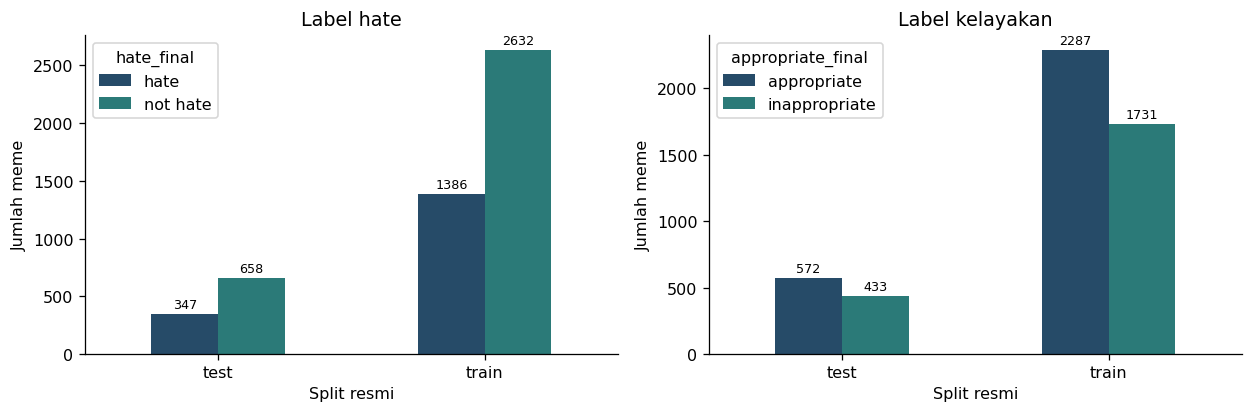

Macro-F1 memberi bobot setara ke setiap kelas, sedangkan accuracy menimbang seluruh baris.


In [4]:
fig,axes=plt.subplots(1,2,figsize=(11,3.7))
for ax,column,title in zip(axes,['hate_final','appropriate_final'],['Label hate','Label kelayakan']):
    counts=pd.crosstab(meta.split,meta[column])
    counts.plot.bar(ax=ax,color=['#264B68','#2B7A78'],rot=0)
    ax.set_title(title);ax.set_xlabel('Split resmi');ax.set_ylabel('Jumlah meme')
    for container in ax.containers:ax.bar_label(container,padding=2,fontsize=8)
fig.tight_layout();plt.show()
print('Macro-F1 memberi bobot setara ke setiap kelas, sedangkan accuracy menimbang seluruh baris.')

### Missing field dan anotasi topik
OCR dan caption berasal dari rilis. Tidak ada regenerasi OCR/caption di eksperimen ini.
Topik kosong menjadi string kosong untuk input model, sedangkan `none/others` dipakai pada tabulasi.
Topik merupakan anotasi tambahan yang belum tentu tersedia ketika sistem menerima meme baru.
Karena itu, hasil dengan topik tidak mewakili pipeline otomatis pengenalan topik.

,Field,Split,Kosong atau nan
0,hate_final,train,0
1,hate_final,test,0
2,appropriate_final,train,0
3,appropriate_final,test,0
4,ocr,train,0
5,ocr,test,0
6,caption,train,0
7,caption,test,0
8,topic,train,179
9,topic,test,49


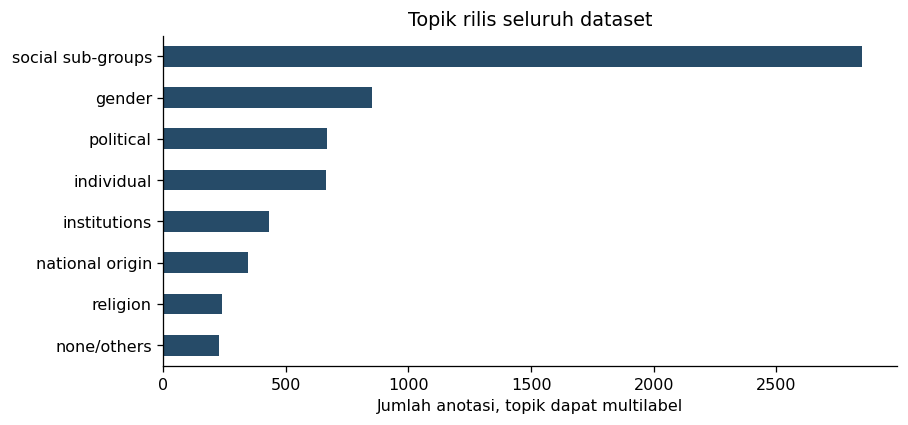

In [5]:
missing=[]
for column in ['hate_final','appropriate_final','ocr','caption','topic']:
    values=meta[column].astype(str).str.strip()
    for split in ['train','test']:
        count=int((values[meta.split==split].isin(['','nan','None'])).sum())
        missing.append({'Field':column,'Split':split,'Kosong atau nan':count})
display(pd.DataFrame(missing))
assert not meta.ocr.astype(str).str.strip().isin(['','nan']).any()
assert not meta.caption.astype(str).str.strip().isin(['','nan']).any()
topic_counts=pd.Series(facts['dataset']['topic_counts']).sort_values()
ax=topic_counts.plot.barh(figsize=(8,3.8),color='#264B68')
ax.set_xlabel('Jumlah anotasi, topik dapat multilabel');ax.set_title('Topik rilis seluruh dataset')
plt.tight_layout();plt.show()

### Split dan duplikat
Train resmi 4.018 dibagi menjadi fit 3.214 dan validation 804 dengan fold pertama
StratifiedGroupKFold lima fold, shuffle, seed 42, dan stratifikasi label gabungan.
Tiga pasang gambar identik di train dikelompokkan. Dua kelompok gambar identik tetap melintasi
train/test resmi. Pemisahan ID tidak sama dengan ketiadaan duplikat visual.

In [6]:
split_sets={}
for identifier in core.id.unique():
    fit=set(read_csv(f'runs/{identifier}/fit_ids.csv').image_path)
    val=set(read_csv(f'runs/{identifier}/validation_ids.csv').image_path)
    pred=read_csv(f'runs/{identifier}/test_predictions.csv')
    test=set(pred.image_path)
    assert len(fit)==3214 and len(val)==804 and len(test)==1005
    assert not fit&val and not fit&test and not val&test
    assert fit|val==set(meta.loc[meta.split=='train','image_path'])
    assert test==set(meta.loc[meta.split=='test','image_path'])
    split_sets[identifier]=(fit,val)
first=next(iter(split_sets.values()))
assert all(value==first for value in split_sets.values())
display(pd.DataFrame([{'Bagian':'Fit','Jumlah':3214},{'Bagian':'Validation','Jumlah':804},{'Bagian':'Test','Jumlah':1005}]))
display(pd.json_normalize(facts['dataset']['duplicate_audit']))
CHECKS['split_ids_eight_runs_checked']=True
print('ID fit/validation identik pada delapan run. Lima kelompok gambar identik meliputi dua kelompok lintas split resmi.')

,Bagian,Jumlah
0,Fit,3214
1,Validation,804
2,Test,1005


,image_path_duplicates.groups,image_path_duplicates.cross_split_groups,image_path_duplicates.rows_in_cross_split_groups,image_sha256_duplicates.groups,image_sha256_duplicates.cross_split_groups,image_sha256_duplicates.rows_in_cross_split_groups,pixel_sha256_duplicates.groups,pixel_sha256_duplicates.cross_split_groups,pixel_sha256_duplicates.rows_in_cross_split_groups
0,0,0,0,5,2,4,5,2,4


ID fit/validation identik pada delapan run. Lima kelompok gambar identik meliputi dua kelompok lintas split resmi.


,screening_completed,images,method,candidate_pairs,exact_pairs_recovered,cross_split_candidate_pairs,nonexact_candidates,manual_review_completed,split_changed,limitation,completed_utc
0,True,5023,"64-bit DCT pHash, Hamming <= 6",197,5,73,192,False,False,Similarity is a screening signal. Crops and larger edits can escape detection; false matches req...,2026-10-23T14:14:49.982052+00:00


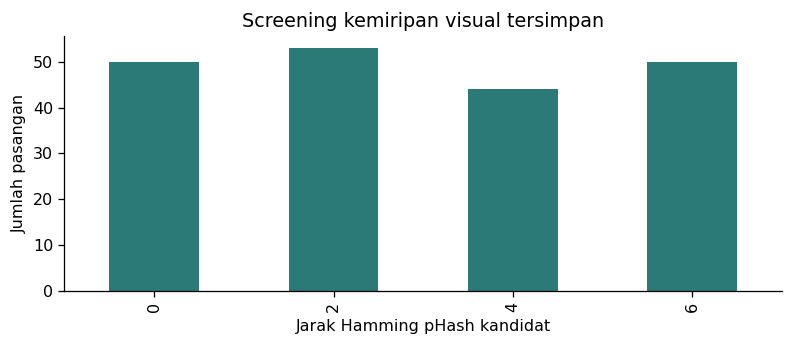

Screening pHash telah dijalankan pada 23 Oktober: 197 pasangan, 73 lintas split, 192 nonexact.
Kandidat pHash adalah sinyal kemiripan. Review manual belum selesai dan split tidak diubah.


In [7]:
phash=read_json('evidence/data_audits/perceptual_audit.json')
phash_pairs=read_csv('evidence/data_audits/perceptual_duplicate_candidates.csv')
assert phash['screening_completed'] and len(phash_pairs)==phash['candidate_pairs']==197
assert phash['cross_split_candidate_pairs']==73
display(pd.DataFrame([phash]))
ax=phash_pairs.groupby('hamming_distance').size().plot.bar(color='#2B7A78',figsize=(7,3.1))
ax.set_xlabel('Jarak Hamming pHash kandidat');ax.set_ylabel('Jumlah pasangan');ax.set_title('Screening kemiripan visual tersimpan')
plt.tight_layout();plt.show()
print('Screening pHash telah dijalankan pada 23 Oktober: 197 pasangan, 73 lintas split, 192 nonexact.')
print('Kandidat pHash adalah sinyal kemiripan. Review manual belum selesai dan split tidak diubah.')

## Preprocessing aktual dan panjang input
Varian bernama Caption+OCR+Topic menggabungkan field tidak kosong dalam urutan **topic, caption, OCR**.
IndoBERTweet memakai separator tokenizer `[SEP]`. Teks dipad/truncate ke 256 token. Pipeline
transformer tidak memakai stemming atau penghapusan stop word. Gambar dibaca sebagai RGB dan
diproses oleh image processor revisi ViT 224 yang dipatok.

,model,variant,rows,median_tokens,p95_tokens,max_tokens,fraction_above_256,separator
0,IndoBERT,OCR,4018,18.0,53.00,185,0.000000,[SEP]
1,IndoBERT,Caption,4018,25.0,32.00,45,0.000000,[SEP]
2,IndoBERT,Caption+OCR,4018,42.0,77.15,213,0.000000,[SEP]
3,IndoBERT,Caption+Topic,4018,30.0,38.00,51,0.000000,[SEP]
4,IndoBERT,OCR+Topic,4018,23.0,58.15,189,0.000000,[SEP]
5,IndoBERT,Caption+OCR+Topic,4018,47.0,83.00,217,0.000000,[SEP]
6,XLM-R,OCR,4018,21.0,62.00,217,0.000000,</s></s>
7,XLM-R,Caption,4018,30.0,38.00,53,0.000000,</s></s>
8,XLM-R,Caption+OCR,4018,52.0,93.00,252,0.000000,</s></s>
9,XLM-R,Caption+Topic,4018,36.0,45.00,60,0.000000,</s></s>


,model,variant,rows,median_tokens,p95_tokens,max_tokens,fraction_above_256,separator
17,IndoBERTweet,Caption+OCR+Topic,4018,48.0,83.0,210,0.0,[SEP]


Audit token memakai train resmi; tidak mengunduh atau memanggil tokenizer lagi pada notebook ini.


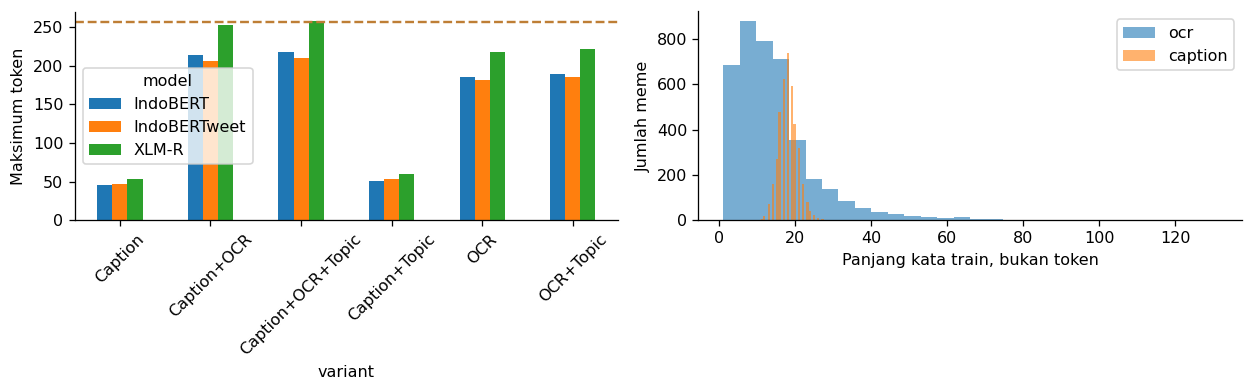

In [8]:
tokens=read_csv('evidence/data_audits/tokenizer_audit_all.csv')
assert len(tokens)==18
display(tokens)
selected_tokens=tokens[(tokens.model=='IndoBERTweet')&(tokens.variant=='Caption+OCR+Topic')]
assert len(selected_tokens)==1
display(selected_tokens)
print('Audit token memakai train resmi; tidak mengunduh atau memanggil tokenizer lagi pada notebook ini.')
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
tokens.pivot(index='variant',columns='model',values='max_tokens').plot.bar(ax=axes[0])
axes[0].axhline(256,color='#BE7E35',linestyle='--',label='Batas256');axes[0].set_ylabel('Maksimum token');axes[0].tick_params(axis='x',rotation=45)
for column in ['ocr','caption']:
    lengths=meta.loc[meta.split=='train',column].astype(str).str.split().str.len()
    axes[1].hist(lengths,bins=30,alpha=.6,label=column)
axes[1].set_xlabel('Panjang kata train, bukan token');axes[1].set_ylabel('Jumlah meme');axes[1].legend()
fig.tight_layout();plt.show()

## Kode implementasi yang digunakan
Bagian berikut menampilkan definisi aktual dari source yang disertakan, tanpa mengimpor atau
memanggil fungsi pelatihan. Dengan demikian, pembaca dapat mengaudit alur pemrosesan dan optimisasi
tanpa menjalankan fine-tuning lagi. Revisi sumber/konfigurasi per run tetap menjadi bukti otoritatif.

In [9]:
def show_source(relative,names):
    source=path(relative).read_text(encoding='utf-8-sig')
    tree=ast.parse(source)
    selected=[node for node in tree.body if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and node.name in names]
    assert {node.name for node in selected}==set(names)
    display(Code((chr(10)*2).join(ast.get_source_segment(source,node) for node in selected),language='python'))
    print('Sumber:',relative,'SHA256:',sha256(path(relative)))

show_source('src/master_training.py',['text_values','MemeDataset'])

def text_values(frame, variant, tokenizer):
    assert tokenizer.sep_token
    fields = VARIANTS[variant]
    separator = ' </s></s> ' if tokenizer.sep_token == '</s>' else ' ' + tokenizer.sep_token + ' '
    return [separator.join(str(row[c]) for c in fields if str(row[c]).strip())
            for row in frame.to_dict('records')]

class MemeDataset(Dataset):
    def __init__(self, frame, images, tokenizer, processor, variant, max_length=256):
        self.frame=frame.reset_index(drop=True); self.images=images; self.processor=processor
        self.tokens=(tokenizer(text_values(self.frame,variant,tokenizer),padding='max_length',truncation=True,
                               max_length=max_length,return_tensors='pt') if tokenizer else {})

    def __len__(self): return len(self.frame)

    def __getitem__(self,index):
        row=self.frame.iloc[index]
        item={'image_path':row.image_path, 'labels':torch.tensor([row.y_hate,row.y_appropriate],dtype=torch.long)}
        item.update({key:value[index] for key,value in self.tokens.items() if key in ['input_ids','attention_mask']})
        if self.processor:
            with Image.open(io.BytesIO(self.images[row.image_path])) as image:
                image.load()
                item['pixel_values']=self.processor(images=image.convert('RGB'),return_tensors='pt')['pixel_values'][0]
        return item

Sumber: src/master_training.py SHA256: 49f14e548d4971e7eec3087186b3f961e9af40e72cc6d2be79ff1b86b62c3c61


In [10]:
show_source('src/master_training.py',['MemeClassifier'])
print('Representasi pooler IndoBERTweet dan ViT dikonkatenasi untuk fusi. Projection linear mengecilkan dimensi menjadi setengah, lalu dropout dan head klasifikasi.')
print('Multitask berbagi representasi dan mempunyai dua head. Model ini tidak menambahkan modul cross-attention baru.')
print('Encoder di-fine-tune pada eksperimen yang telah selesai, bukan dibekukan sebagai pengganti metode.')

class MemeClassifier(nn.Module):
    def __init__(self,config):
        super().__init__()
        from transformers import AutoModel, CLIPVisionModel
        self.config=config; self.text_encoder=None; self.image_encoder=None; dim=0
        for family in ['text','image']:
            if family not in config['models']: continue
            m=config['models'][family]
            cls=CLIPVisionModel if family=='image' and config['image']=='CLIP' else AutoModel
            # Original IndoBERT/IndoBERTweet releases provide .bin; PyTorch >=2.6 loads weights safely.
            assert tuple(map(int,torch.__version__.split('+')[0].split('.')[:2])) >= (2,6)
            encoder=cls.from_pretrained(m['id'],revision=m['revision'])
            setattr(self,family+'_encoder',encoder); dim+=encoder.config.hidden_size
        assert dim>0
        self.dropout=nn.Dropout(config['dropout'])
        needs_projection=config['kind']=='multimodal' or config['task']=='both'
        self.shared=nn.Sequential(nn.Linear(dim,dim//2),nn.Dropout(config['dropout'])) if needs_projection else nn.Identity()
        out_dim=dim//2 if needs_projection else dim
        self.heads=nn.ModuleDict({task:nn.Linear(out_dim,2) for task in
                                (['hate','appropriate'] if config['task']=='both' else [config['task']])})

    def forward(self,batch):
        features=[]
        if self.text_encoder is not None:
            text=self.text_encoder(input_ids=batch['input_ids'],attention_mask=batch['attention_mask'])
            features.append(text.pooler_output)
        if self.image_encoder is not None:
            image=self.image_encoder(pixel_values=batch['pixel_values'])
            features.append(image.last_hidden_state.mean(dim=1) if self.config['image']=='SwinV2' else image.pooler_output)
        feature=torch.cat(features,dim=1) if len(features)>1 else features[0]
        if self.config['kind']=='text': feature=self.dropout(feature)
        elif self.config['kind']=='image' and self.config['task']!='both': feature=self.dropout(feature)
        shared=self.shared(feature)
        return {task:head(shared) for task,head in self.heads.items()}

Sumber: src/master_training.py SHA256: 49f14e548d4971e7eec3087186b3f961e9af40e72cc6d2be79ff1b86b62c3c61
Representasi pooler IndoBERTweet dan ViT dikonkatenasi untuk fusi. Projection linear mengecilkan dimensi menjadi setengah, lalu dropout dan head klasifikasi.
Multitask berbagi representasi dan mempunyai dua head. Model ini tidak menambahkan modul cross-attention baru.
Encoder di-fine-tune pada eksperimen yang telah selesai, bukan dibekukan sebagai pengganti metode.


In [11]:
show_source('src/master_training.py',['total_loss','evaluate'])
print('Loss multitask = 0,5 cross-entropy hate + 0,5 cross-entropy inappropriate.')
print('Aturan constrained: prediksi inappropriate = maksimum(prediksi raw inappropriate, prediksi hate).')
print('Raw disimpan; evaluasi inappropriate multitask utama memakai constrained.')

def total_loss(logits,labels,lambda_hate):
    terms={task:nn.functional.cross_entropy(value,labels[:,0 if task=='hate' else 1]) for task,value in logits.items()}
    if len(terms)==2: return lambda_hate*terms['hate']+(1-lambda_hate)*terms['appropriate']
    return next(iter(terms.values()))

def evaluate(model,loader,device):
    model.eval(); records=[]
    with torch.no_grad():
        for batch in loader:
            labels=batch['labels']; names=batch['image_path']
            inputs={k:v.to(device) for k,v in batch.items() if k not in ['image_path','labels']}
            logits=model(inputs)
            for task,values in logits.items():
                prob=values.softmax(-1).cpu().numpy(); pred=prob.argmax(-1)
                for i,name in enumerate(names):
                    records.append({'image_path':name,'task':task,'truth':int(labels[i,0 if task=='hate' else 1]),
                                    'prediction':int(pred[i]),'probability_positive':float(prob[i,1])})
    frame=pd.DataFrame(records)
    scores={task:metrics(group.truth.to_numpy(),group.prediction.to_numpy()) for task,group in frame.groupby('task')}
    if set(scores)=={'hate','appropriate'}:
        h=frame[frame.task=='hate'].set_index('image_path'); a=frame[frame.task=='appropriate'].set_index('image_path')
        constrained=np.maximum(a.prediction.to_numpy(),h.loc[a.index,'prediction'].to_numpy())
        scores['appropriate_constrained']=metrics(a.truth.to_numpy(),constrained)
        frame['prediction_constrained']=frame.prediction
        frame.loc[frame.task=='appropriate','prediction_constrained']=constrained
    return scores,frame

Sumber: src/master_training.py SHA256: 49f14e548d4971e7eec3087186b3f961e9af40e72cc6d2be79ff1b86b62c3c61
Loss multitask = 0,5 cross-entropy hate + 0,5 cross-entropy inappropriate.
Aturan constrained: prediksi inappropriate = maksimum(prediksi raw inappropriate, prediksi hate).
Raw disimpan; evaluasi inappropriate multitask utama memakai constrained.


In [12]:
show_source('src/master_training.py',['run_training','lock_test_protocol','evaluate_official_test'])
print('Definisi di atas hanya ditampilkan. Tidak satu pun fungsi training atau inference dipanggil.')

def run_training(root,config,fit,val,images):
    from transformers import get_linear_schedule_with_warmup
    root=Path(root); seed_all(config['seed'])
    assert config['split_sha256']==digest(root/'splits/train_validation.csv')
    payload=json.dumps(config,sort_keys=True,separators=(',',':'))
    run_id=config['experiment_id']+'__'+hashlib.sha256(payload.encode()).hexdigest()[:12]
    run=root/'runs'/run_id; run.mkdir(parents=True,exist_ok=True)
    if (run/'result.json').exists():
        print('Hasil tersimpan dimuat:',run_id)
        return json.loads((run/'result.json').read_text()),run
    save_json(run/'config.json',config)
    train_frame=capped(fit,config['max_train'],config['seed']); val_frame=capped(val,config['max_validation'],config['seed'])
    train_frame[['image_path']].to_csv(run/'fit_ids.csv',index=False); val_frame[['image_path']].to_csv(run/'validation_ids.csv',index=False)
    assert not set(train_frame.image_path)&set(val_frame.image_path)
    tokenizer,processor=tokenizer_and_processor(config)
    train_data=MemeDataset(train_frame,images,tokenizer,processor,config['variant'],config['max_length'])
    val_data=MemeDataset(val_frame,images,tokenizer,processor,config['variant'],config['max_length'])
    val_loader=DataLoader(val_data,batch_size=config['batch_size'],shuffle=False,num_workers=0)
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model=MemeClassifier(config).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['learning_rate'],weight_decay=config['weight_decay'])
    steps_per_epoch=math.ceil(math.ceil(len(train_data)/config['batch_size'])/config['gradient_accumulation'])
    scheduler=get_linear_schedule_with_warmup(optimizer,0,steps_per_epoch*config['epochs'])
    start_epoch=0; best=-1.; bad_epochs=0; history=[]
    if (run/'last.pt').exists():
        checkpoint=torch.load(run/'last.pt',map_location=device,weights_only=True)
        assert checkpoint['config_json']==payload
        model.load_state_dict(checkpoint['model']); optimizer.load_state_dict(checkpoint['optimizer']); scheduler.load_state_dict(checkpoint['scheduler'])
        start_epoch=checkpoint['epoch']+1; best=checkpoint['best']; bad_epochs=checkpoint['bad_epochs']; history=checkpoint['history']
        print('Melanjutkan dari epoch selesai:',start_epoch)
    for epoch in range(start_epoch,config['epochs']):
        if bad_epochs>=config['patience']: break
        seed_all(config['seed']+epoch)
        generator=torch.Generator().manual_seed(config['seed']+epoch)
        loader=DataLoader(train_data,batch_size=config['batch_size'],shuffle=True,generator=generator,num_workers=0)
        model.train(); optimizer.zero_grad(set_to_none=True); losses=[]
        for step,batch in enumerate(loader):
            inputs={k:v.to(device) for k,v in batch.items() if k not in ['image_path','labels']}
            loss=total_loss(model(inputs),batch['labels'].to(device),config['lambda_hate'])
            assert torch.isfinite(loss).item(), 'Loss tidak terhingga; hentikan run.'
            count=min(config['gradient_accumulation'],len(loader)-(step//config['gradient_accumulation'])*config['gradient_accumulation'])
            (loss/count).backward(); losses.append(float(loss.detach().cpu()))
            if (step+1)%config['gradient_accumulation']==0 or step+1==len(loader):
                torch.nn.utils.clip_grad_norm_(model.parameters(),1.0,error_if_nonfinite=True)
                optimizer.step(); scheduler.step(); optimizer.zero_grad(set_to_none=True)
        scores,predictions=evaluate(model,val_loader,device)
        primary=float(np.mean([scores['appropriate_constrained' if t=='appropriate' and len(model.heads)==2 else t]['macro_f1']
                               for t in model.heads]))
        history.append({'epoch':epoch+1,'train_loss':float(np.mean(losses)),'selection_macro_f1':primary,
                        **{task+'_macro_f1':s['macro_f1'] for task,s in scores.items()}})
        i

Sumber: src/master_training.py SHA256: 49f14e548d4971e7eec3087186b3f961e9af40e72cc6d2be79ff1b86b62c3c61
Definisi di atas hanya ditampilkan. Tidak satu pun fungsi training atau inference dipanggil.


### Protokol dan deviasi
Seed 42, maksimum 5 epoch, AdamW, learning rate 2e-5, weight decay 0,01, dropout 0,3, precision FP32,
warmup 0, dan patience 2. Batch historis 2 × akumulasi 4 serta lab 1 × akumulasi 8 memberi batch efektif
sekitar 8, tetapi tidak menjamin trajektori optimisasi identik.

Checkpoint single-task dipilih dari Macro-F1 validation. Multitask memakai rata-rata hate dan
constrained inappropriate. History dan resume checkpoint disimpan tiap epoch. Prediksi/metrik
validation serta best checkpoint diperbarui saat skor seleksi membaik. Test memakai checkpoint
yang sudah terkunci. Lambda 0,5 belum mereproduksi proses tuning lambda penulis.

In [13]:
configuration_rows=[]
for identifier in core.id.unique():
    cfg=read_json(f'runs/{identifier}/config.json')
    assert cfg['seed']==42 and cfg['scope']=='full' and cfg['max_train'] is None and cfg['max_validation'] is None
    configuration_rows.append({'ID':identifier,'Kind':cfg['kind'],'Task':cfg['task'],
        'Physical batch':cfg['batch_size'],'Accumulation':cfg['gradient_accumulation'],
        'Precision':cfg['precision'],'LR':cfg['learning_rate'],'Selection':cfg['selection_metric']})
display(pd.DataFrame(configuration_rows))
display(pd.DataFrame(facts['protocol'].items(),columns=['Parameter','Nilai']))
deviations=[]
for run in facts['runs']:
    for note in run['config']['deviations']:
        if note not in deviations:deviations.append(note)
display(pd.DataFrame({'Deviasi yang tercatat':deviations}))

,ID,Kind,Task,Physical batch,Accumulation,Precision,LR,Selection
0,E005,image,hate,2,4,float32,0.00002,macro-F1
1,E006,image,appropriate,1,8,float32,0.00002,macro-F1
2,E041,text,hate,2,4,float32,0.00002,macro-F1
3,E042,text,appropriate,2,4,float32,0.00002,macro-F1
4,E059,multimodal,hate,1,8,float32,0.00002,macro-F1
5,E060,multimodal,appropriate,2,4,float32,0.00002,macro-F1
6,E101,text,both,1,8,float32,0.00002,"mean(hate macro-F1, constrained inappropriate macro-F1)"
7,E110,multimodal,both,1,8,float32,0.00002,"mean(hate macro-F1, constrained inappropriate macro-F1)"


,Parameter,Nilai
0,seed,42
1,max_epochs,5
2,learning_rate,0.00002
3,optimizer,AdamW
4,weight_decay,0.01
5,dropout,0.3
6,max_length,256
7,precision,FP32
8,warmup_steps,0
9,scheduler,linear


,Deviasi yang tercatat
0,validation derived from official train; selection by validation macro-F1
1,physical batch 2 x accumulation 4 approximates source batch 8; FP32
2,"early stopping patience 2, warmup 0; clarify with authors"
3,multitask lambda is an explicit candidate; validation tuning must be documented
4,model revisions pinned on first use; original author training revisions unknown
5,pooler_output follows source; article pooled-CLS wording requires clarification
6,XLM-R double </s></s> follows RQ2 article input diagram; RQ4 prose/source differ
7,unimodal dual-head projection follows author code; article prose omits its dimension
8,"ViT checkpoint follows article (224-in21k), differs from active source 384"
9,appropriate positive label is inappropriate; macro metrics unchanged by remapping


## Register status seluruh pekerjaan
Jumlah konfigurasi inti, keluaran tugas, baseline validation, smoke test, dan percobaan gagal
dilaporkan terpisah. Satu model multitask menghasilkan dua hasil tugas. Kalibrasi satu batch
tidak dihitung sebagai training penuh. Riwayat gagal tidak menghapus keberhasilan run berikutnya.

In [14]:
register=[]
for run in facts['runs']:
    register.append({'ID':run['id'],'Kelompok':'Paket inti','Status':'Completed test','Epoch':run['epochs_trained'],
                     'Hasil tugas':2 if run['config']['task']=='both' else 1})
for run in inventory['supplementary_supervised']:
    register.append({'ID':run['id'],'Kelompok':'Supervised historis di luar paket inti','Status':run['status'],
                     'Epoch':len(run.get('history',[])),'Hasil tugas':1 if run.get('test_metrics') else 0})
display(pd.DataFrame(register))
display(pd.DataFrame([{'Jenis':'Konfigurasi inti selesai','Jumlah':8},{'Jenis':'Hasil tugas inti','Jumlah':10},
 {'Jenis':'Baseline validation tambahan','Jumlah':len(inventory['baseline_trials'])},
 {'Jenis':'Kalibrasi atau smoke record','Jumlah':len(inventory.get('calibrations',[]))}]))

,ID,Kelompok,Status,Epoch,Hasil tugas
0,E005,Paket inti,Completed test,5,1
1,E006,Paket inti,Completed test,4,1
2,E041,Paket inti,Completed test,4,1
3,E042,Paket inti,Completed test,4,1
4,E059,Paket inti,Completed test,4,1
5,E060,Paket inti,Completed test,4,1
6,E101,Paket inti,Completed test,5,2
7,E110,Paket inti,Completed test,5,2
8,E001,Supervised historis di luar paket inti,completed_test_historical_outside_core,4,1
9,E002,Supervised historis di luar paket inti,partial_deferred_scope_no_test,3,0


,Jenis,Jumlah
0,Konfigurasi inti selesai,8
1,Hasil tugas inti,10
2,Baseline validation tambahan,14
3,Kalibrasi atau smoke record,3


## Baseline konvensional validation
Empat belas baseline terdiri dari Majority serta enam varian TF-IDF dan logistic regression
untuk dua tugas. Pengujian menggunakan validation 804 dari train resmi. Hasil ini adalah sanity
baseline tambahan, bukan reproduksi model transformer paper dan bukan skor test 1.005.
Vectorizer dipasang hanya pada fit. Tidak ada training ulang baseline di notebook ini.

In [15]:
baseline_config=read_json(inventory['baseline_trials'][0]['config_path'])
display(pd.DataFrame([{'Parameter':key,'Nilai':baseline_config[key]} for key in
 ['evaluation','seed','split','fit_rows','validation_rows','separator','tfidf','logreg','selection','topic_note']]))
show_source('src/baseline_text.py',['partition','text_input','run_baselines'])
print('Definisi baseline hanya diperlihatkan. Fit logistic regression tidak dijalankan ulang.')

,Parameter,Nilai
0,evaluation,validation only; official 1005-row test never evaluated
1,seed,42
2,split,"First fold StratifiedGroupKFold(5, shuffle=True, seed=42); joint labels"
3,fit_rows,3214
4,validation_rows,804
5,separator,literal [SEP] between components; not transformer tokenization
6,tfidf,"{'analyzer': 'word', 'ngram_range': [1, 2], 'min_df': 2, 'max_features': 30000, 'sublinear_tf': ..."
7,logreg,"{'C': 1.0, 'class_weight': 'balanced', 'solver': 'liblinear', 'max_iter': 1000}"
8,selection,No hyperparameter search; 6 prespecified variants. Report all validation results.
9,topic_note,Provided annotated topic is privileged input; not automatically available at deployment.


def partition(rows):
    names = {row['image_path'] for row in rows}
    assert all(set(pair) <= names for pair in TRAIN_DUPLICATES)
    duplicate_map = {name: pair[0] for pair in TRAIN_DUPLICATES for name in pair}
    groups = np.array([duplicate_map.get(row['image_path'], row['image_path']) for row in rows])
    joint = [row['hate_final'] + '|' + row['appropriate_final'] for row in rows]
    fit, val = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
                    .split(np.zeros(len(rows)), joint, groups))
    assert not set(groups[fit]) & set(groups[val]), 'Duplikat lintas train/validation.'
    assert len(fit) + len(val) == len(rows)
    assert set(joint[i] for i in fit) == set(joint[i] for i in val) == set(joint)
    return fit, val, groups

def text_input(row, fields):
    return ' [SEP] '.join(row[field] for field in fields if row[field].strip())

def run_baselines(archive='data/INDOMEME_Dataset.zip', output_root='runs'):
    rows = load_training(archive)
    fit, val, groups = partition(rows)
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    output = Path(output_root) / ('baseline_text_' + run_id)
    output.mkdir(parents=True, exist_ok=False)
    with (output / 'split_manifest.csv').open('w', newline='', encoding='utf-8') as handle:
        writer = csv.writer(handle)
        writer.writerow(['image_path', 'partition', 'exact_image_group'])
        val_set = set(val.tolist())
        writer.writerows((row['image_path'], 'validation' if i in val_set else 'train', groups[i])
                         for i, row in enumerate(rows))
    config = {
        'purpose': 'Additional sanity baseline, not reproduction of a paper model',
        'evaluation': 'validation only; official 1005-row test never evaluated',
        'seed': SEED, 'split': 'First fold StratifiedGroupKFold(5, shuffle=True, seed=42); joint labels',
        'fit_rows': len(fit), 'validation_rows': len(val), 'data_url': DATA_URL, 'zip_sha256': ZIP_SHA,
        'image_audit_revision': '3e0cb8cae9cd726582f69afdb122163d0eab108b',
        'train_exact_duplicate_pairs': TRAIN_DUPLICATES,
        'variants': VARIANTS, 'separator': 'literal [SEP] between components; not transformer tokenization',
        'tfidf': {'analyzer': 'word', 'ngram_range': [1, 2], 'min_df': 2, 'max_features': 30000,
                  'sublinear_tf': True, 'lowercase': True},
        'logreg': {'C': 1.0, 'class_weight': 'balanced', 'solver': 'liblinear', 'max_iter': 1000},
        'selection': 'No hyperparameter search; 6 prespecified variants. Report all validation results.',
        'topic_note': 'Provided annotated topic is privileged input; not automatically available at deployment.',
        'label_map': {'hate': {'not hate': 0, 'hate': 1},
                      'appropriate': {'appropriate': 0, 'inappropriate': 1}},
        'versions': {pkg: importlib.metadata.version(pkg) for pkg in
                     ['numpy', 'scipy', 'scikit-learn', 'joblib', 'threadpoolctl']},
        'python': platform.python_version(), 'platform': platform.platform(), 'created_utc': run_id,
        'split_sha256': hashlib.sha256((output / 'split_manifest.csv').read_bytes()).hexdigest(),
        'class_distribution': {part: dict(Counter(rows[i]['hate_final'] + '|' + rows[i]['appropriate_final']
                                                for i in indices)) for part, indices in [('train', fit), ('validation', val)]},
    }
    if '__file__' in globals():
        config['script_sha256'] = hashlib.sha256(Path(__file__).read_bytes()).hexdigest()
    (output / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
    results, predictions = [], []
    start = time.perf_counter()
    with warnings.catch_warnings(), threadpool_limits(limits=2):
        warnings.simplefilter('error', ConvergenceWarning)
        for task, column, positive in [('hate', 'hate_final', 'hate'),
                                       ('appropriate', 'appropriate_final'

Sumber: src/baseline_text.py SHA256: 10e09cdede5d408565313d13a4fbada3e61bcb834f3f727ff99e21dffdf68e73
Definisi baseline hanya diperlihatkan. Fit logistic regression tidak dijalankan ulang.


In [16]:
def manual_metrics(truth,prediction):
    truth=np.asarray(truth,dtype=int);prediction=np.asarray(prediction,dtype=int)
    assert len(truth)==len(prediction)>0 and set(truth)<= {0,1} and set(prediction)<= {0,1}
    cm=np.zeros((2,2),dtype=int)
    for y,pred in zip(truth,prediction):cm[y,pred]+=1
    per=[]
    for label in [0,1]:
        tp=int(cm[label,label]);support=int(cm[label].sum());predicted=int(cm[:,label].sum())
        precision=tp/predicted if predicted else 0.;recall=tp/support if support else 0.
        f1=2*precision*recall/(precision+recall) if precision+recall else 0.
        per.append({'label':label,'precision':precision,'recall':recall,'f1':f1,'support':support})
    result={'macro_precision':np.mean([r['precision'] for r in per]),'macro_recall':np.mean([r['recall'] for r in per]),
      'macro_f1':np.mean([r['f1'] for r in per]),'accuracy':float(np.trace(cm)/cm.sum()),
      'confusion_matrix_labels_0_1':cm.tolist(),'per_class':per,'rows':len(truth)}
    sk=precision_recall_fscore_support(truth,prediction,labels=[0,1],average='macro',zero_division=0)
    assert np.allclose([result['macro_precision'],result['macro_recall'],result['macro_f1']],sk[:3],atol=1e-12,rtol=0)
    assert abs(result['accuracy']-accuracy_score(truth,prediction))<1e-12
    return result

assert manual_metrics([0,0,1,1],[0,0,0,0])['macro_f1']==1/3
assert manual_metrics([0,1],[0,1])['macro_f1']==1
baseline_rows=[]
for trial in inventory['baseline_trials']:
    frame=read_csv(trial['predictions_path'])
    for key,value in trial['prediction_filter'].items():frame=frame[frame[key]==value]
    assert set(frame.image_path)==first[1] and frame.image_path.is_unique
    truth_column='y_hate' if trial['task']=='hate' else 'y_appropriate'
    assert np.array_equal(frame.truth.astype(int),meta.set_index('image_path').loc[frame.image_path,truth_column].astype(int).to_numpy())
    result=manual_metrics(frame.truth,frame.prediction)
    assert result['rows']==trial['rows']==804
    for key in ['macro_precision','macro_recall','macro_f1','accuracy']:
        assert abs(result[key]-trial['metrics'][key])<1e-12
    baseline_rows.append({'ID':trial['trial_id'],'Task':trial['task'],'Variant':trial['variant'],
      **{key:result[key] for key in ['macro_precision','macro_recall','macro_f1','accuracy']}})
    CHECKS['baseline_validation_trials']+=1
baseline=pd.DataFrame(baseline_rows)
assert len(baseline)==14
display(baseline)

,ID,Task,Variant,macro_precision,macro_recall,macro_f1,accuracy
0,B01,hate,Majority,0.330224,0.500000,0.397753,0.660448
1,B02,hate,OCR,0.726356,0.731690,0.728749,0.753731
2,B03,hate,Caption,0.731496,0.735457,0.733334,0.758706
3,B04,hate,Caption+OCR,0.756037,0.754186,0.755087,0.781095
4,B05,hate,Caption+Topic,0.779324,0.781762,0.780504,0.802239
5,B06,hate,OCR+Topic,0.767555,0.762608,0.764925,0.791045
6,B07,hate,Caption+OCR+Topic,0.788077,0.786521,0.787285,0.809701
7,B08,appropriate,Majority,0.282338,0.500000,0.360890,0.564677
8,B09,appropriate,OCR,0.682376,0.682008,0.682182,0.687811
9,B10,appropriate,Caption,0.715294,0.714242,0.714712,0.720149


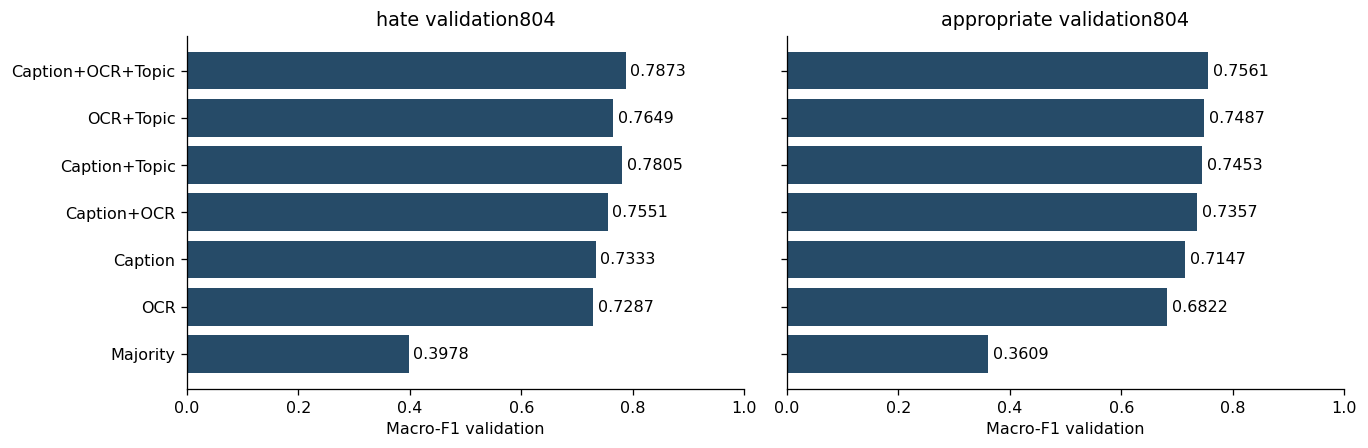

### B01  hate  Majority

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B01,hate,Majority,validation,804,0.330224,0.5,0.397753,0.660448


,label,precision,recall,f1,support
0,0,0.660448,1.0,0.795506,531
1,1,0.000000,0.0,0.000000,273


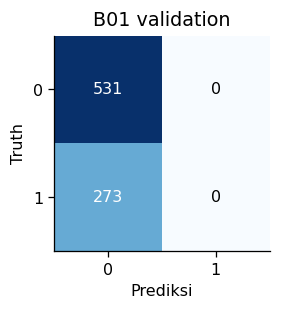

Tidak ada contoh false positive pada artefak trial ini.


,Jenis,ID gambar,Truth,Prediksi
0,False negative,1000970594176012.jpeg,1,0
1,False negative,10028998933828616.jpeg,1,0
2,False negative,1005662505024622.jpeg,1,0


Insight B01: Macro-F1 validation 0.3978, accuracy 0.6604, FP 0, dan FN 273.
Model mayoritas memprediksi kelas 0. Recall kelas positif bernilai nol, sehingga accuracy tidak cukup untuk menilai deteksi kelas positif.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B02  hate  OCR

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B02,hate,OCR,validation,804,0.726356,0.73169,0.728749,0.753731


,label,precision,recall,f1,support
0,0,0.822050,0.800377,0.811069,531
1,1,0.630662,0.663004,0.646429,273


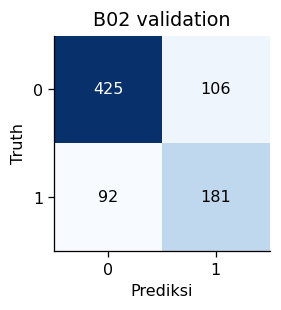

,Jenis,ID gambar,Truth,Prediksi
0,False positive,1003786335117124.jpeg,0,1
1,False positive,1015554067273684.jpeg,0,1
2,False positive,1015929580664581.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,10028998933828616.jpeg,1,0
5,False negative,1008906851325638.jpeg,1,0


Insight B02: Macro-F1 validation 0.7287, accuracy 0.7537, FP 106, dan FN 92.
Pada validation yang sama, selisih Macro-F1 terhadap Majority adalah +33.0996 poin persentase.
Varian ini tidak memakai anotasi topik.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B03  hate  Caption

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B03,hate,Caption,validation,804,0.731496,0.735457,0.733334,0.758706


,label,precision,recall,f1,support
0,0,0.823417,0.807910,0.815589,531
1,1,0.639576,0.663004,0.651079,273


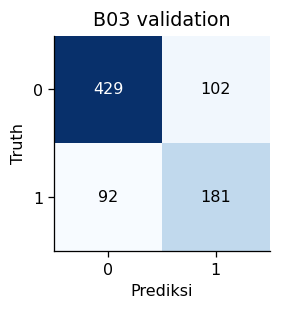

,Jenis,ID gambar,Truth,Prediksi
0,False positive,10007163152657541.jpeg,0,1
1,False positive,1007367488109132.jpeg,0,1
2,False positive,1011980094297748.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1014177377411353.jpeg,1,0
5,False negative,1019493313546426.jpeg,1,0


Insight B03: Macro-F1 validation 0.7333, accuracy 0.7587, FP 102, dan FN 92.
Pada validation yang sama, selisih Macro-F1 terhadap OCR adalah +0.4586 poin persentase.
Varian ini tidak memakai anotasi topik.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B04  hate  Caption+OCR

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B04,hate,Caption+OCR,validation,804,0.756037,0.754186,0.755087,0.781095


,label,precision,recall,f1,support
0,0,0.831776,0.838041,0.834897,531
1,1,0.680297,0.670330,0.675277,273


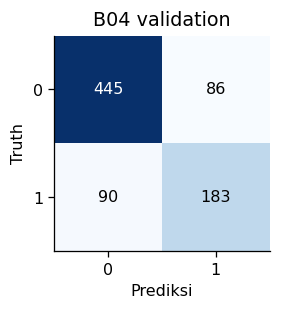

,Jenis,ID gambar,Truth,Prediksi
0,False positive,10007163152657541.jpeg,0,1
1,False positive,1011980094297748.jpeg,0,1
2,False positive,1015554067273684.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1008906851325638.jpeg,1,0
5,False negative,1014177377411353.jpeg,1,0


Insight B04: Macro-F1 validation 0.7551, accuracy 0.7811, FP 86, dan FN 90.
Pada validation yang sama, selisih Macro-F1 terhadap Caption adalah +2.1753 poin persentase.
Varian ini tidak memakai anotasi topik.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B05  hate  Caption+Topic

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B05,hate,Caption+Topic,validation,804,0.779324,0.781762,0.780504,0.802239


,label,precision,recall,f1,support
0,0,0.853612,0.845574,0.849574,531
1,1,0.705036,0.717949,0.711434,273


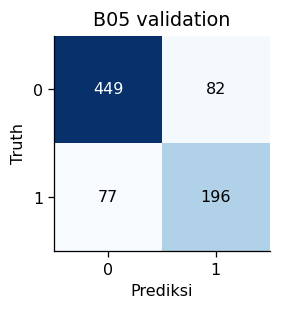

,Jenis,ID gambar,Truth,Prediksi
0,False positive,1012961894349537.jpeg,0,1
1,False positive,1015554067273684.jpeg,0,1
2,False positive,10226711980337261.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1014177377411353.jpeg,1,0
5,False negative,1034570022038755.jpeg,1,0


Insight B05: Macro-F1 validation 0.7805, accuracy 0.8022, FP 82, dan FN 77.
Pada validation yang sama, selisih Macro-F1 terhadap Caption adalah +4.7170 poin persentase.
Varian ini memakai topik anotasi rilis. Hasil tidak mewakili sistem yang harus memprediksi topik meme baru.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B06  hate  OCR+Topic

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B06,hate,OCR+Topic,validation,804,0.767555,0.762608,0.764925,0.791045


,label,precision,recall,f1,support
0,0,0.83549,0.851224,0.843284,531
1,1,0.69962,0.673993,0.686567,273


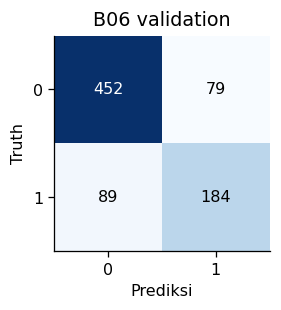

,Jenis,ID gambar,Truth,Prediksi
0,False positive,1015554067273684.jpeg,0,1
1,False positive,10226711980337261.jpeg,0,1
2,False positive,10226835553266507.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1014177377411353.jpeg,1,0
5,False negative,1047970220698735.jpeg,1,0


Insight B06: Macro-F1 validation 0.7649, accuracy 0.7910, FP 79, dan FN 89.
Pada validation yang sama, selisih Macro-F1 terhadap OCR adalah +3.6177 poin persentase.
Varian ini memakai topik anotasi rilis. Hasil tidak mewakili sistem yang harus memprediksi topik meme baru.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B07  hate  Caption+OCR+Topic

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B07,hate,Caption+OCR+Topic,validation,804,0.788077,0.786521,0.787285,0.809701


,label,precision,recall,f1,support
0,0,0.853933,0.858757,0.856338,531
1,1,0.722222,0.714286,0.718232,273


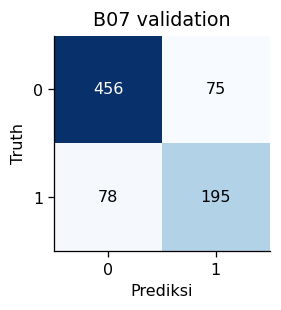

,Jenis,ID gambar,Truth,Prediksi
0,False positive,1012961894349537.jpeg,0,1
1,False positive,1015554067273684.jpeg,0,1
2,False positive,10226711980337261.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1014177377411353.jpeg,1,0
5,False negative,1034570022038755.jpeg,1,0


Insight B07: Macro-F1 validation 0.7873, accuracy 0.8097, FP 75, dan FN 78.
Pada validation yang sama, selisih Macro-F1 terhadap Caption+OCR adalah +3.2198 poin persentase.
Varian ini memakai topik anotasi rilis. Hasil tidak mewakili sistem yang harus memprediksi topik meme baru.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B08  appropriate  Majority

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B08,appropriate,Majority,validation,804,0.282338,0.5,0.36089,0.564677


,label,precision,recall,f1,support
0,0,0.564677,1.0,0.721781,454
1,1,0.000000,0.0,0.000000,350


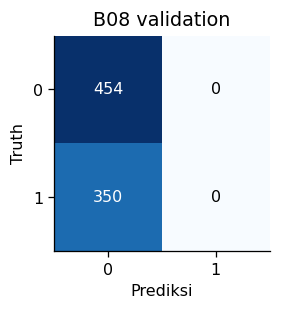

Tidak ada contoh false positive pada artefak trial ini.


,Jenis,ID gambar,Truth,Prediksi
0,False negative,1000970594176012.jpeg,1,0
1,False negative,10028998933828616.jpeg,1,0
2,False negative,1005662505024622.jpeg,1,0


Insight B08: Macro-F1 validation 0.3609, accuracy 0.5647, FP 0, dan FN 350.
Model mayoritas memprediksi kelas 0. Recall kelas positif bernilai nol, sehingga accuracy tidak cukup untuk menilai deteksi kelas positif.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B09  appropriate  OCR

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B09,appropriate,OCR,validation,804,0.682376,0.682008,0.682182,0.687811


,label,precision,recall,f1,support
0,0,0.722101,0.726872,0.724479,454
1,1,0.642651,0.637143,0.639885,350


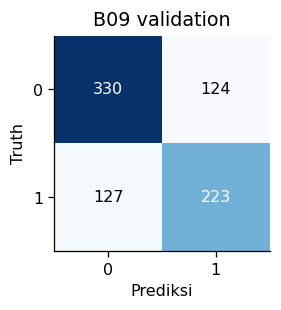

,Jenis,ID gambar,Truth,Prediksi
0,False positive,1011980094297748.jpeg,0,1
1,False positive,1015554067273684.jpeg,0,1
2,False positive,1015929580664581.jpeg,0,1
3,False negative,10028998933828616.jpeg,1,0
4,False negative,1008906851325638.jpeg,1,0
5,False negative,1027329446094679.jpeg,1,0


Insight B09: Macro-F1 validation 0.6822, accuracy 0.6878, FP 124, dan FN 127.
Pada validation yang sama, selisih Macro-F1 terhadap Majority adalah +32.1292 poin persentase.
Varian ini tidak memakai anotasi topik.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B10  appropriate  Caption

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B10,appropriate,Caption,validation,804,0.715294,0.714242,0.714712,0.720149


,label,precision,recall,f1,support
0,0,0.748373,0.759912,0.754098,454
1,1,0.682216,0.668571,0.675325,350


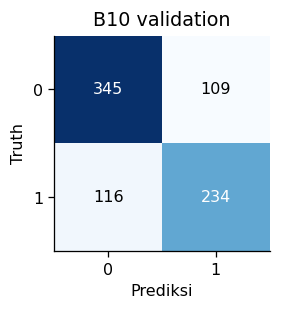

,Jenis,ID gambar,Truth,Prediksi
0,False positive,10007163152657541.jpeg,0,1
1,False positive,1007367488109132.jpeg,0,1
2,False positive,1011980094297748.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1014177377411353.jpeg,1,0
5,False negative,1019493313546426.jpeg,1,0


Insight B10: Macro-F1 validation 0.7147, accuracy 0.7201, FP 109, dan FN 116.
Pada validation yang sama, selisih Macro-F1 terhadap OCR adalah +3.2530 poin persentase.
Varian ini tidak memakai anotasi topik.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B11  appropriate  Caption+OCR

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B11,appropriate,Caption+OCR,validation,804,0.738914,0.734065,0.735734,0.742537


,label,precision,recall,f1,support
0,0,0.757829,0.799559,0.778135,454
1,1,0.720000,0.668571,0.693333,350


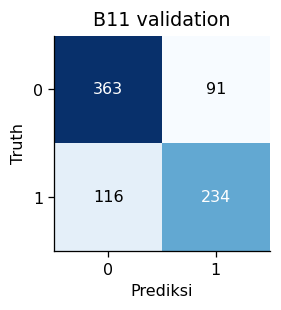

,Jenis,ID gambar,Truth,Prediksi
0,False positive,10007163152657541.jpeg,0,1
1,False positive,1011980094297748.jpeg,0,1
2,False positive,1015929580664581.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1014177377411353.jpeg,1,0
5,False negative,1019493313546426.jpeg,1,0


Insight B11: Macro-F1 validation 0.7357, accuracy 0.7425, FP 91, dan FN 116.
Pada validation yang sama, selisih Macro-F1 terhadap Caption adalah +2.1023 poin persentase.
Varian ini tidak memakai anotasi topik.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B12  appropriate  Caption+Topic

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B12,appropriate,Caption+Topic,validation,804,0.745771,0.744928,0.745319,0.75


,label,precision,recall,f1,support
0,0,0.775599,0.784141,0.779847,454
1,1,0.715942,0.705714,0.710791,350


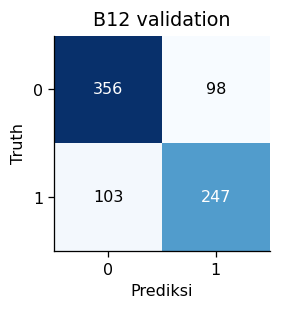

,Jenis,ID gambar,Truth,Prediksi
0,False positive,1011980094297748.jpeg,0,1
1,False positive,1012961894349537.jpeg,0,1
2,False positive,1015554067273684.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1014177377411353.jpeg,1,0
5,False negative,1034570022038755.jpeg,1,0


Insight B12: Macro-F1 validation 0.7453, accuracy 0.7500, FP 98, dan FN 103.
Pada validation yang sama, selisih Macro-F1 terhadap Caption adalah +3.0607 poin persentase.
Varian ini memakai topik anotasi rilis. Hasil tidak mewakili sistem yang harus memprediksi topik meme baru.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B13  appropriate  OCR+Topic

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B13,appropriate,OCR+Topic,validation,804,0.751668,0.747042,0.748705,0.754975


,label,precision,recall,f1,support
0,0,0.769392,0.808370,0.78840,454
1,1,0.733945,0.685714,0.70901,350


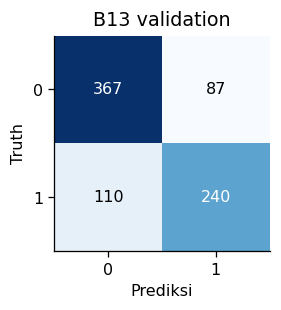

,Jenis,ID gambar,Truth,Prediksi
0,False positive,1012961894349537.jpeg,0,1
1,False positive,1015554067273684.jpeg,0,1
2,False positive,10226711980337261.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1034570022038755.jpeg,1,0
5,False negative,1047970220698735.jpeg,1,0


Insight B13: Macro-F1 validation 0.7487, accuracy 0.7550, FP 87, dan FN 110.
Pada validation yang sama, selisih Macro-F1 terhadap OCR adalah +6.6523 poin persentase.
Varian ini memakai topik anotasi rilis. Hasil tidak mewakili sistem yang harus memprediksi topik meme baru.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


### B14  appropriate  Caption+OCR+Topic

,ID,Tugas,Varian,Evaluasi,Jumlah,macro_precision,macro_recall,macro_f1,accuracy
0,B14,appropriate,Caption+OCR+Topic,validation,804,0.757422,0.755167,0.756117,0.761194


,label,precision,recall,f1,support
0,0,0.781116,0.801762,0.791304,454
1,1,0.733728,0.708571,0.720930,350


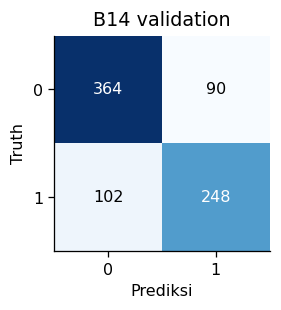

,Jenis,ID gambar,Truth,Prediksi
0,False positive,1011980094297748.jpeg,0,1
1,False positive,1012961894349537.jpeg,0,1
2,False positive,1015554067273684.jpeg,0,1
3,False negative,1000970594176012.jpeg,1,0
4,False negative,1014177377411353.jpeg,1,0
5,False negative,1034570022038755.jpeg,1,0


Insight B14: Macro-F1 validation 0.7561, accuracy 0.7612, FP 90, dan FN 102.
Pada validation yang sama, selisih Macro-F1 terhadap Caption+OCR adalah +2.0383 poin persentase.
Varian ini memakai topik anotasi rilis. Hasil tidak mewakili sistem yang harus memprediksi topik meme baru.
Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.


In [17]:
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,task in zip(axes,['hate','appropriate']):
    subset=baseline[baseline.Task==task]
    bars=ax.barh(subset.Variant,subset.macro_f1,color='#264B68')
    ax.bar_label(bars,fmt='%.4f',padding=3);ax.set_xlim(0,1)
    ax.set_title(task+' validation804');ax.set_xlabel('Macro-F1 validation')
fig.tight_layout();plt.show()
for trial in inventory['baseline_trials']:
    display(Markdown(f"### {trial['trial_id']}  {trial['task']}  {trial['variant']}"))
    m=trial['metrics']
    display(pd.DataFrame([{'ID':trial['trial_id'],'Tugas':trial['task'],'Varian':trial['variant'],
       'Evaluasi':'validation','Jumlah':trial['rows'],
       **{key:m[key] for key in ['macro_precision','macro_recall','macro_f1','accuracy']}}]))
    display(pd.DataFrame(m['per_class']))
    cm=np.array(m['confusion_matrix_labels_0_1'])
    fig,ax=plt.subplots(figsize=(3.3,2.8));ax.imshow(cm,cmap='Blues')
    for i in range(2):
        for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
    ax.set(xticks=[0,1],yticks=[0,1],xlabel='Prediksi',ylabel='Truth',title=trial['trial_id']+' validation')
    fig.tight_layout();plt.show()
    error_rows=[]
    for kind,label in [('false_positive','False positive'),('false_negative','False negative')]:
        examples=trial.get('error_examples',{}).get(kind,[])
        if not examples:print('Tidak ada contoh '+label.lower()+' pada artefak trial ini.')
        for example in examples:
            error_rows.append({'Jenis':label,'ID gambar':example['image_path'],
                               'Truth':example['truth'],'Prediksi':example['prediction']})
    if error_rows:display(pd.DataFrame(error_rows))
    print(f"Insight {trial['trial_id']}: Macro-F1 validation {m['macro_f1']:.4f}, accuracy {m['accuracy']:.4f}, FP {cm[0,1]}, dan FN {cm[1,0]}.")
    if trial['variant']=='Majority':
        print('Model mayoritas memprediksi kelas 0. Recall kelas positif bernilai nol, sehingga accuracy tidak cukup untuk menilai deteksi kelas positif.')
    else:
        reference_variant={'OCR':'Majority','Caption':'OCR','Caption+OCR':'Caption',
            'Caption+Topic':'Caption','OCR+Topic':'OCR','Caption+OCR+Topic':'Caption+OCR'}[trial['variant']]
        reference=next(item for item in inventory['baseline_trials']
                       if item['task']==trial['task'] and item['variant']==reference_variant)
        difference=100*(m['macro_f1']-reference['metrics']['macro_f1'])
        print(f"Pada validation yang sama, selisih Macro-F1 terhadap {reference_variant} adalah {difference:+.4f} poin persentase.")
        if 'Topic' in trial['variant']:
            print('Varian ini memakai topik anotasi rilis. Hasil tidak mewakili sistem yang harus memprediksi topik meme baru.')
        else:print('Varian ini tidak memakai anotasi topik.')
    print('Hasil hanya berlaku pada validation 804 dan satu seed. Contoh error bersifat deterministik, tanpa anotasi penyebab semantik atau klaim signifikansi.')

## Analisis per eksperimen inti
Bagian berikut membahas setiap ID secara utuh: konfigurasi dan riwayat, evaluasi validation/test,
confusion matrix, kelas positif, contoh kesalahan, perbandingan paper, serta insight teramati.
Angka dihitung ulang dari CSV prediksi yang dibekukan. Perbedaan validation/test tidak dengan
sendirinya membuktikan penyebab overfitting atau kualitas anotasi.

In [18]:
RUN_RESULTS={}

def prediction_result(identifier,split,task,policy):
    frame=read_csv(f'runs/{identifier}/{split}_predictions.csv')
    frame=frame[frame.task==task].copy()
    assert len(frame)==(1005 if split=='test' else 804) and frame.image_path.is_unique
    labels=meta.set_index('image_path')['y_hate' if task=='hate' else 'y_appropriate'].astype(int)
    assert np.array_equal(frame.truth.astype(int),labels.loc[frame.image_path].to_numpy())
    column='prediction_constrained' if policy=='constrained' else 'prediction'
    assert column in frame
    frame['evaluated_prediction']=frame[column].astype(int)
    return manual_metrics(frame.truth,frame.evaluated_prediction),frame

def plot_cm_panels(records):
    rows=(len(records)+1)//2
    fig,axes=plt.subplots(rows,2,figsize=(8,3.3*rows),squeeze=False)
    for ax,(title,result) in zip(axes.flat,records):
        cm=np.array(result['confusion_matrix_labels_0_1']);ax.imshow(cm,cmap='Blues',vmin=0,vmax=650)
        for i in range(2):
            for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=13,color='white' if cm[i,j]>350 else '#172733')
        ax.set(xticks=[0,1],yticks=[0,1],xlabel='Prediksi',ylabel='Truth',title=title)
    for ax in list(axes.flat)[len(records):]:ax.axis('off')
    fig.tight_layout();plt.show()

def describe_run(identifier):
    config=read_json(f'runs/{identifier}/config.json')
    result=read_json(f'runs/{identifier}/result.json')
    history=read_csv(f'runs/{identifier}/history.csv')
    reference=next(r for r in facts['runs'] if r['id']==identifier)
    best=history.loc[history.selection_macro_f1.astype(float).idxmax()]
    assert int(best.epoch)==reference['selected_epoch']
    display(pd.DataFrame([{'ID':identifier,'Run ID':result.get('run_id',reference['config']['experiment_id']),
       'Kind':config['kind'],'Task':config['task'],'Batch':config['batch_size'],
       'Akumulasi':config['gradient_accumulation'],'Epoch jalan':len(history),'Epoch dipilih':int(best.epoch),
       'Config SHA256':sha256(path(f'runs/{identifier}/config.json'))}]))
    display(pd.json_normalize(config['models']))
    display(history)
    fig,axes=plt.subplots(1,2,figsize=(10,3.1))
    axes[0].plot(history.epoch,history.train_loss,marker='o',color='#2B7A78');axes[0].set(xlabel='Epoch',ylabel='Train loss',title=identifier+' loss')
    axes[1].plot(history.epoch,history.selection_macro_f1,marker='o',label='Skor seleksi validation')
    axes[1].axvline(int(best.epoch),ls='--',color='#BE7E35',label='Checkpoint pilihan')
    axes[1].set(xlabel='Epoch',ylabel='Macro-F1 seleksi',title=identifier+' validation');axes[1].legend(fontsize=8)
    for ax in axes:ax.set_xticks(history.epoch);ax.grid(alpha=.15)
    fig.tight_layout();plt.show()
    print('Status: completed test. Epoch yang dijalankan dan epoch checkpoint terpilih dibedakan.')

def evaluate_run(identifier):
    relevant=[o for o in facts['outcomes'] if o['id']==identifier]
    metrics_rows=[];classes=[];panels=[]
    for outcome in relevant:
        task=outcome['task'];policy=outcome['policy']
        for split in ['validation','test']:
            computed,frame=prediction_result(identifier,split,task,policy)
            expected=outcome['validation'] if split=='validation' else outcome['test']
            for key in ['macro_precision','macro_recall','macro_f1','accuracy']:
                assert abs(computed[key]-expected[key])<1e-12,(identifier,task,split,key)
            RUN_RESULTS[(identifier,task,split)]=(computed,frame)
            metrics_rows.append({'Split':split,'Tugas':task,'Policy':policy,**{k:computed[k] for k in ['macro_precision','macro_recall','macro_f1','accuracy']}})
            classes.extend({'Split':split,'Task':task,**r} for r in computed['per_class'])
            panels.append((identifier+' '+task+' '+split,computed))
            if split=='test':CHECKS['core_test_outcomes']+=1
        if policy=='constrained':
            raw,_=prediction_result(identifier,'test',task,'raw')
            metrics_rows.append({'Split':'test tambahan','Tugas':task,'Policy':'raw',**{k:raw[k] for k in ['macro_precision','macro_recall','macro_f1','accuracy']}})
    display(pd.DataFrame(metrics_rows));display(pd.DataFrame(classes))
    plot_cm_panels(panels)
    print('Baris=truth, kolom=prediksi. Kelas1=hate pada hate dan inappropriate pada appropriate.')

def inspect_errors(identifier):
    for outcome in [o for o in facts['outcomes'] if o['id']==identifier]:
        task=outcome['task'];m,frame=RUN_RESULTS[(identifier,task,'test')]
        errors=frame[frame.truth.astype(int)!=frame.evaluated_prediction].copy()
        errors['Jenis']=np.where(errors.truth.astype(int)==0,'false positive','false negative')
        examples=pd.concat([group.sort_values('image_path').head(3) for _,group in errors.groupby('Jenis')])
        display(Markdown('#### '+identifier+' '+task+' contoh kesalahan'))
        display(examples[['image_path','truth','evaluated_prediction','Jenis']])
        joined=frame.merge(meta[['image_path','joint_label']],on='image_path',validate='one_to_one')
        joined['correct']=(joined.truth.astype(int)==joined.evaluated_prediction)
        display(joined.groupby('joint_label').agg(Jumlah=('correct','size'),Benar=('correct','sum'),Proporsi_benar=('correct','mean')))
        cm=m['confusion_matrix_labels_0_1'];positive=m['per_class'][1]
        print(f"{identifier} {task}: FP={cm[0][1]}, FN={cm[1][0]}, recall kelas1={positive['recall']:.4f}.")
        print(f"Macro-F1 validation={outcome['validation_macro_f1']:.4f}, test={m['macro_f1']:.4f}, paper={outcome['paper_macro_f1']:.3f}, delta={outcome['delta_percentage_points']:+.2f} pp.")
        print('Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.')

### E005 Gambar ViT untuk hate

Gambar saja memberi baseline modalitas. Recall hate yang teramati dibandingkan dengan model teks, tanpa menyimpulkan bahwa penyebabnya selalu teks di dalam meme.

,ID,Run ID,Kind,Task,Batch,Akumulasi,Epoch jalan,Epoch dipilih,Config SHA256
0,E005,RQ2__image__ViT__-__-__hate__68f0e71edabc,image,hate,2,4,5,3,ec4a41f7372ce5f5c0845cc56c0054c137eeab86efbbd4599af285f6d7a78738


,image.id,image.revision
0,google/vit-base-patch32-224-in21k,98cb6f7099d372694c8547bf7002289b36857dc7


,epoch,train_loss,selection_macro_f1,hate_macro_f1
0,1,0.624436,0.614305,0.614305
1,2,0.491934,0.625116,0.625116
2,3,0.300180,0.640726,0.640726
3,4,0.130644,0.625875,0.625875
4,5,0.050227,0.625574,0.625574


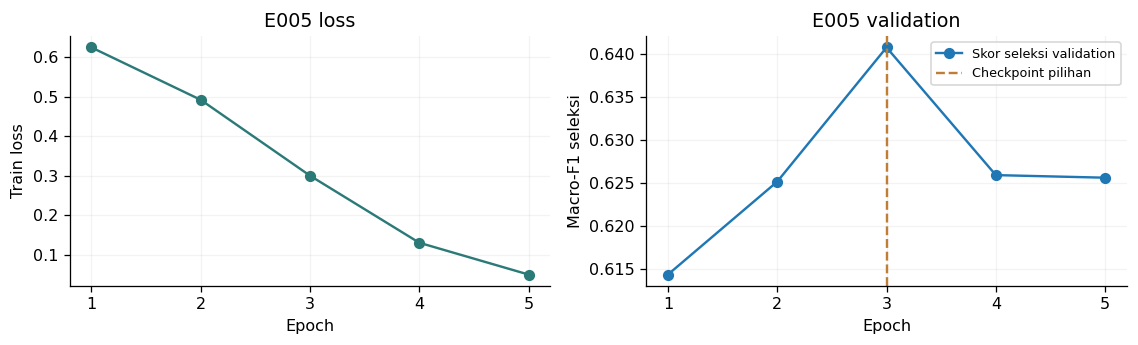

Status: completed test. Epoch yang dijalankan dan epoch checkpoint terpilih dibedakan.


In [19]:
describe_run('E005')

,Split,Tugas,Policy,macro_precision,macro_recall,macro_f1,accuracy
0,validation,hate,raw,0.642003,0.639649,0.640726,0.680348
1,test,hate,raw,0.642515,0.639463,0.640813,0.678607


,Split,Task,label,precision,recall,f1,support
0,validation,hate,0,0.753704,0.766478,0.760037,531
1,validation,hate,1,0.530303,0.512821,0.521415,273
2,test,hate,0,0.748886,0.765957,0.757325,658
3,test,hate,1,0.536145,0.512968,0.524300,347


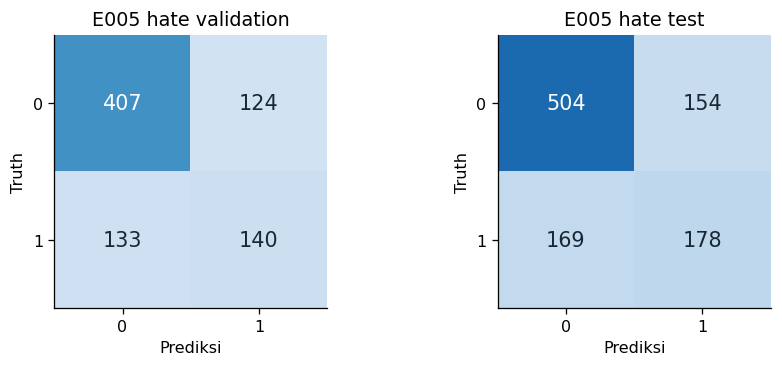

Baris=truth, kolom=prediksi. Kelas1=hate pada hate dan inappropriate pada appropriate.


In [20]:
evaluate_run('E005')

In [21]:
inspect_errors('E005')
print('Gambar saja memberi baseline modalitas. Recall hate yang teramati dibandingkan dengan model teks, tanpa menyimpulkan bahwa penyebabnya selalu teks di dalam meme.')

#### E005 hate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
748,1001507855343505.jpeg,1,0,false negative
7,10030062560388920.jpeg,1,0,false negative
366,1007401798184026.jpeg,1,0,false negative
993,1009879063039334.jpeg,0,1,false positive
925,1018563468837560.jpeg,0,1,false positive
570,1020425740269819.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,178,0.512968
not hate | appropriate,572,444,0.776224
not hate | inappropriate,86,60,0.697674


E005 hate: FP=154, FN=169, recall kelas1=0.5130.
Macro-F1 validation=0.6407, test=0.6408, paper=0.630, delta=+1.08 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.
Gambar saja memberi baseline modalitas. Recall hate yang teramati dibandingkan dengan model teks, tanpa menyimpulkan bahwa penyebabnya selalu teks di dalam meme.


### E006 Gambar ViT untuk inappropriate

Run lab berhenti normal pada epoch4 setelah checkpoint terbaik epoch2. Ini early stopping, bukan training yang gagal.

,ID,Run ID,Kind,Task,Batch,Akumulasi,Epoch jalan,Epoch dipilih,Config SHA256
0,E006,RQ2__image__ViT__-__-__appropriate__5987b0691760,image,appropriate,1,8,4,2,f5ccfe1d81c7be91dadf467ebb379ba44f615d87ce55f6f27a6d383d9e7a9fb2


,image.id,image.revision
0,google/vit-base-patch32-224-in21k,98cb6f7099d372694c8547bf7002289b36857dc7


,epoch,train_loss,selection_macro_f1,appropriate_macro_f1
0,1,0.668118,0.610739,0.610739
1,2,0.528727,0.634784,0.634784
2,3,0.330583,0.634721,0.634721
3,4,0.155882,0.620395,0.620395


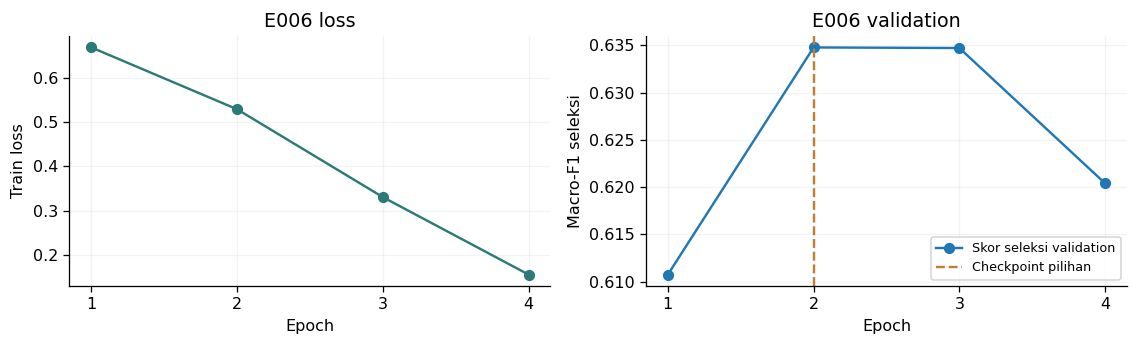

Status: completed test. Epoch yang dijalankan dan epoch checkpoint terpilih dibedakan.


In [22]:
describe_run('E006')

,Split,Tugas,Policy,macro_precision,macro_recall,macro_f1,accuracy
0,validation,appropriate,raw,0.634665,0.634921,0.634784,0.640547
1,test,appropriate,raw,0.632644,0.630844,0.631455,0.640796


,Split,Task,label,precision,recall,f1,support
0,validation,appropriate,0,0.682927,0.678414,0.680663,454
1,validation,appropriate,1,0.586402,0.591429,0.588905,350
2,test,appropriate,0,0.677909,0.702797,0.690129,572
3,test,appropriate,1,0.587379,0.558891,0.572781,433


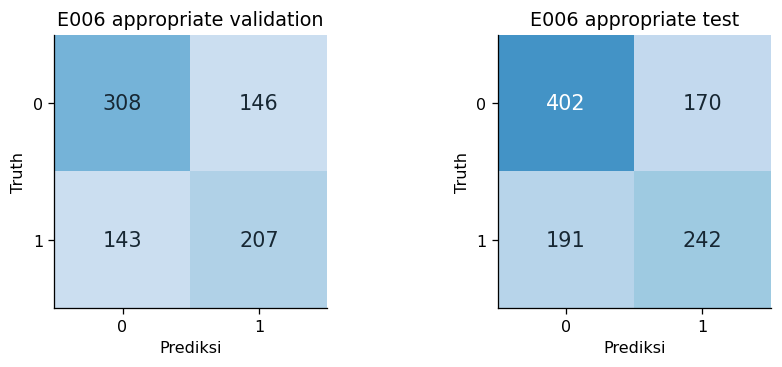

Baris=truth, kolom=prediksi. Kelas1=hate pada hate dan inappropriate pada appropriate.


In [23]:
evaluate_run('E006')

In [24]:
inspect_errors('E006')
print('Run lab berhenti normal pada epoch4 setelah checkpoint terbaik epoch2. Ini early stopping, bukan training yang gagal.')

#### E006 appropriate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
748,1001507855343505.jpeg,1,0,false negative
7,10030062560388920.jpeg,1,0,false negative
544,1003541394914516.jpeg,1,0,false negative
43,1018494587129601.jpeg,0,1,false positive
925,1018563468837560.jpeg,0,1,false positive
570,1020425740269819.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,207,0.596542
not hate | appropriate,572,402,0.702797
not hate | inappropriate,86,35,0.406977


E006 appropriate: FP=170, FN=191, recall kelas1=0.5589.
Macro-F1 validation=0.6348, test=0.6315, paper=0.630, delta=+0.15 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.
Run lab berhenti normal pada epoch4 setelah checkpoint terbaik epoch2. Ini early stopping, bukan training yang gagal.


### E041 IndoBERTweet untuk hate

Input memakai topik, caption, dan OCR. Model teks ini menjadi pembanding fusi hate, dengan konteks topik anotasi yang sama.

,ID,Run ID,Kind,Task,Batch,Akumulasi,Epoch jalan,Epoch dipilih,Config SHA256
0,E041,RQ2__text__-__IndoBERTweet__Caption+OCR+Topic__hate__b9e0ab78cc4d,text,hate,2,4,4,2,40d7b1dceb42c40b5ddba36a567858b9e58a3beea1c41c994e5f8669edd67ac3


,text.id,text.revision
0,indolem/indobertweet-base-uncased,32e28c05b47e33b6675d2670a1745c50a65e987a


,epoch,train_loss,selection_macro_f1,hate_macro_f1
0,1,0.484556,0.739364,0.739364
1,2,0.373829,0.820765,0.820765
2,3,0.266235,0.816122,0.816122
3,4,0.148984,0.810505,0.810505


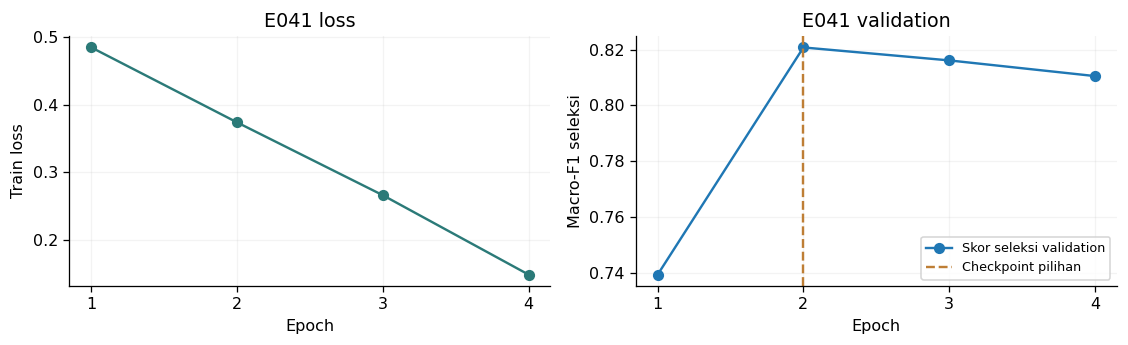

Status: completed test. Epoch yang dijalankan dan epoch checkpoint terpilih dibedakan.


In [25]:
describe_run('E041')

,Split,Tugas,Policy,macro_precision,macro_recall,macro_f1,accuracy
0,validation,hate,raw,0.827337,0.815453,0.820765,0.842040
1,test,hate,raw,0.810729,0.801720,0.805800,0.826866


,Split,Task,label,precision,recall,f1,support
0,validation,hate,0,0.867273,0.898305,0.882516,531
1,validation,hate,1,0.787402,0.732601,0.759013,273
2,test,hate,0,0.856932,0.882979,0.869760,658
3,test,hate,1,0.764526,0.720461,0.741840,347


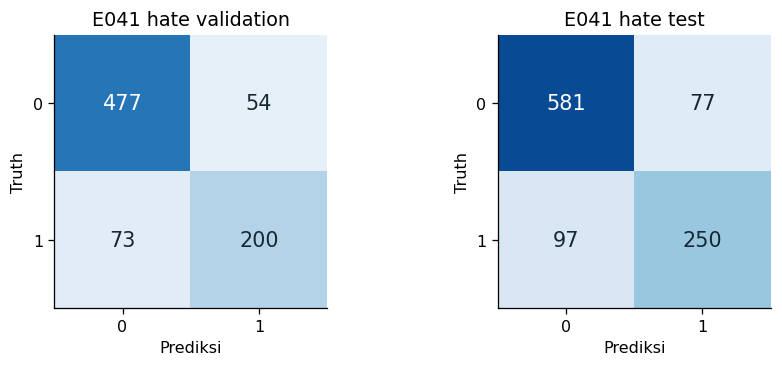

Baris=truth, kolom=prediksi. Kelas1=hate pada hate dan inappropriate pada appropriate.


In [26]:
evaluate_run('E041')

In [27]:
inspect_errors('E041')
print('Input memakai topik, caption, dan OCR. Model teks ini menjadi pembanding fusi hate, dengan konteks topik anotasi yang sama.')

#### E041 hate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
7,10030062560388920.jpeg,1,0,false negative
902,1010091771207146.jpeg,1,0,false negative
639,1026441909518233.jpeg,1,0,false negative
925,1018563468837560.jpeg,0,1,false positive
174,1019254657053594.jpeg,0,1,false positive
980,1030872669007324.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,250,0.720461
not hate | appropriate,572,515,0.900350
not hate | inappropriate,86,66,0.767442


E041 hate: FP=77, FN=97, recall kelas1=0.7205.
Macro-F1 validation=0.8208, test=0.8058, paper=0.800, delta=+0.58 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.
Input memakai topik, caption, dan OCR. Model teks ini menjadi pembanding fusi hate, dengan konteks topik anotasi yang sama.


### E042 IndoBERTweet untuk inappropriate

Kandidat berdasarkan validation per tugas. Kandidat ini tidak dipilih karena memiliki test tertinggi. Margin validation terhadap E110 sangat kecil.

,ID,Run ID,Kind,Task,Batch,Akumulasi,Epoch jalan,Epoch dipilih,Config SHA256
0,E042,RQ2__text__-__IndoBERTweet__Caption+OCR+Topic__appropriate__f369557dad2e,text,appropriate,2,4,4,2,62307a2cd79deb37af9f3188ddc6e397f3c57219d11b35a2e932dc062aebd05e


,text.id,text.revision
0,indolem/indobertweet-base-uncased,32e28c05b47e33b6675d2670a1745c50a65e987a


,epoch,train_loss,selection_macro_f1,appropriate_macro_f1
0,1,0.533945,0.758893,0.758893
1,2,0.411203,0.792355,0.792355
2,3,0.279357,0.777554,0.777554
3,4,0.158771,0.776988,0.776988


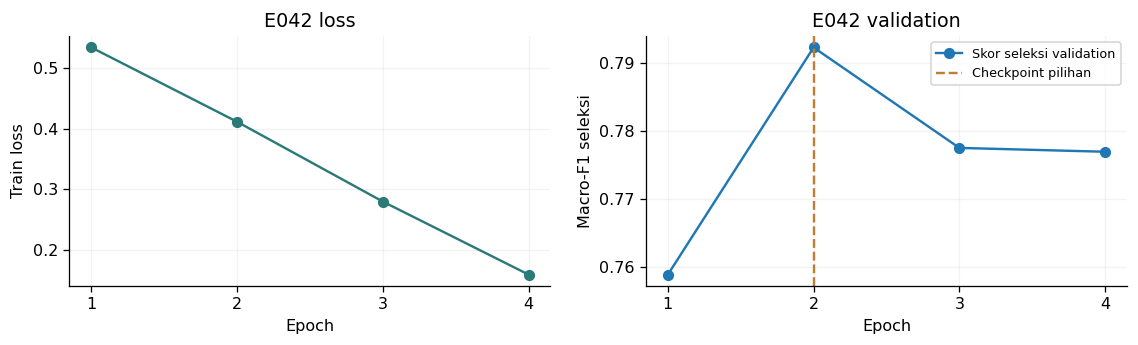

Status: completed test. Epoch yang dijalankan dan epoch checkpoint terpilih dibedakan.


In [28]:
describe_run('E042')

,Split,Tugas,Policy,macro_precision,macro_recall,macro_f1,accuracy
0,validation,appropriate,raw,0.806789,0.787791,0.792355,0.800995
1,test,appropriate,raw,0.811355,0.793660,0.798413,0.806965


,Split,Task,label,precision,recall,f1,support
0,validation,appropriate,0,0.785992,0.889868,0.834711,454
1,validation,appropriate,1,0.827586,0.685714,0.750000,350
2,test,appropriate,0,0.795312,0.889860,0.839934,572
3,test,appropriate,1,0.827397,0.697460,0.756892,433


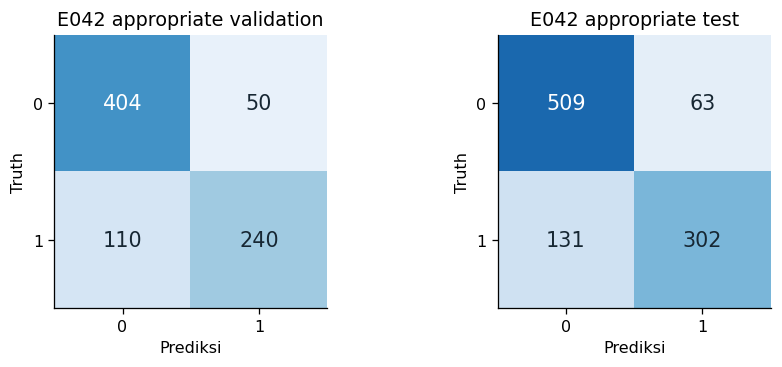

Baris=truth, kolom=prediksi. Kelas1=hate pada hate dan inappropriate pada appropriate.


In [29]:
evaluate_run('E042')

In [30]:
inspect_errors('E042')
print('Kandidat berdasarkan validation per tugas. Kandidat ini tidak dipilih karena memiliki test tertinggi. Margin validation terhadap E110 sangat kecil.')

#### E042 appropriate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
748,1001507855343505.jpeg,1,0,false negative
7,10030062560388920.jpeg,1,0,false negative
544,1003541394914516.jpeg,1,0,false negative
925,1018563468837560.jpeg,0,1,false positive
174,1019254657053594.jpeg,0,1,false positive
135,1035902948572129.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,254,0.731988
not hate | appropriate,572,509,0.889860
not hate | inappropriate,86,48,0.558140


E042 appropriate: FP=63, FN=131, recall kelas1=0.6975.
Macro-F1 validation=0.7924, test=0.7984, paper=0.788, delta=+1.04 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.
Kandidat berdasarkan validation per tugas. Kandidat ini tidak dipilih karena memiliki test tertinggi. Margin validation terhadap E110 sangat kecil.


### E059 Fusi ViT dan IndoBERTweet untuk hate

Run yang berhasil merupakan kelanjutan setelah kegagalan OOM terdahulu dengan konfigurasi eksekusi baru. Fusi tidak memperbaiki Macro-F1 test hate dibanding E041 pada seed ini.

,ID,Run ID,Kind,Task,Batch,Akumulasi,Epoch jalan,Epoch dipilih,Config SHA256
0,E059,RQ2__multimodal__ViT__IndoBERTweet__Caption+OCR+Topic__hate__814050361203,multimodal,hate,1,8,4,2,62e724edfd57791263cf1ba93a3e8254c809e78f2daef99474e9dab6e798f94d


,image.id,image.revision,text.id,text.revision
0,google/vit-base-patch32-224-in21k,98cb6f7099d372694c8547bf7002289b36857dc7,indolem/indobertweet-base-uncased,32e28c05b47e33b6675d2670a1745c50a65e987a


,epoch,train_loss,selection_macro_f1,hate_macro_f1
0,1,0.485603,0.801641,0.801641
1,2,0.326291,0.829291,0.829291
2,3,0.189228,0.819747,0.819747
3,4,0.077272,0.809674,0.809674


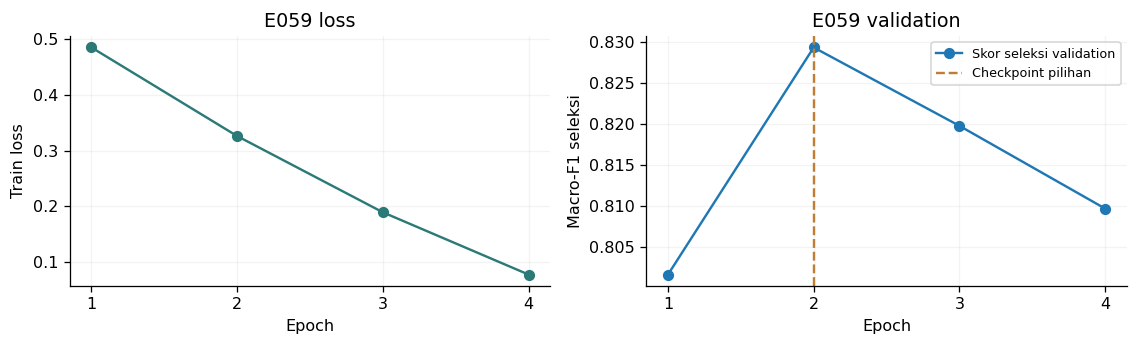

Status: completed test. Epoch yang dijalankan dan epoch checkpoint terpilih dibedakan.


In [31]:
describe_run('E059')

,Split,Tugas,Policy,macro_precision,macro_recall,macro_f1,accuracy
0,validation,hate,raw,0.832538,0.826390,0.829291,0.848259
1,test,hate,raw,0.805827,0.802845,0.804286,0.823881


,Split,Task,label,precision,recall,f1,support
0,validation,hate,0,0.878004,0.894539,0.886194,531
1,validation,hate,1,0.787072,0.758242,0.772388,273
2,test,hate,0,0.861654,0.870821,0.866213,658
3,test,hate,1,0.750000,0.734870,0.742358,347


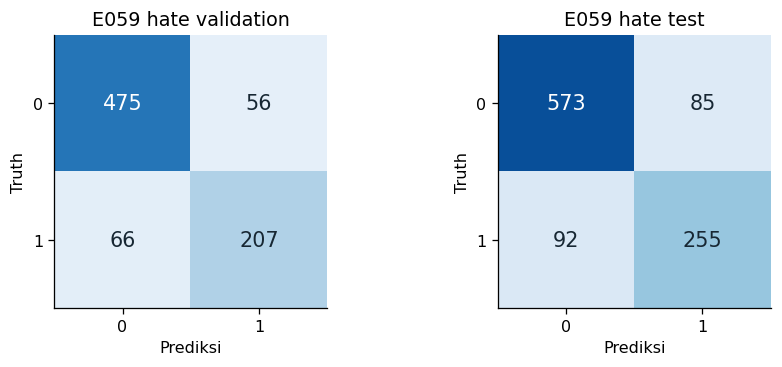

Baris=truth, kolom=prediksi. Kelas1=hate pada hate dan inappropriate pada appropriate.


In [32]:
evaluate_run('E059')

In [33]:
inspect_errors('E059')
print('Run yang berhasil merupakan kelanjutan setelah kegagalan OOM terdahulu dengan konfigurasi eksekusi baru. Fusi tidak memperbaiki Macro-F1 test hate dibanding E041 pada seed ini.')

#### E059 hate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
7,10030062560388920.jpeg,1,0,false negative
902,1010091771207146.jpeg,1,0,false negative
639,1026441909518233.jpeg,1,0,false negative
925,1018563468837560.jpeg,0,1,false positive
174,1019254657053594.jpeg,0,1,false positive
980,1030872669007324.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,255,0.734870
not hate | appropriate,572,511,0.893357
not hate | inappropriate,86,62,0.720930


E059 hate: FP=85, FN=92, recall kelas1=0.7349.
Macro-F1 validation=0.8293, test=0.8043, paper=0.820, delta=-1.57 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.
Run yang berhasil merupakan kelanjutan setelah kegagalan OOM terdahulu dengan konfigurasi eksekusi baru. Fusi tidak memperbaiki Macro-F1 test hate dibanding E041 pada seed ini.


### E060 Fusi ViT dan IndoBERTweet untuk inappropriate

Macro-F1 test inappropriate tertinggi pada paket inti teramati pada E060. Skor validation-nya lebih rendah daripada E042, sehingga keduanya tidak boleh dipertukarkan sebagai pemenang test dan kandidat validation.

,ID,Run ID,Kind,Task,Batch,Akumulasi,Epoch jalan,Epoch dipilih,Config SHA256
0,E060,RQ2__multimodal__ViT__IndoBERTweet__Caption+OCR+Topic__appropriate__c48c7095d0be,multimodal,appropriate,2,4,4,2,bf6c7520a9dc4954b4a7156569f014243029412d2ebbd50c5330a5a464c47f4e


,image.id,image.revision,text.id,text.revision
0,google/vit-base-patch32-224-in21k,98cb6f7099d372694c8547bf7002289b36857dc7,indolem/indobertweet-base-uncased,32e28c05b47e33b6675d2670a1745c50a65e987a


,epoch,train_loss,selection_macro_f1,appropriate_macro_f1
0,1,0.537049,0.767561,0.767561
1,2,0.364437,0.784890,0.784890
2,3,0.187020,0.770170,0.770170
3,4,0.071080,0.770170,0.770170


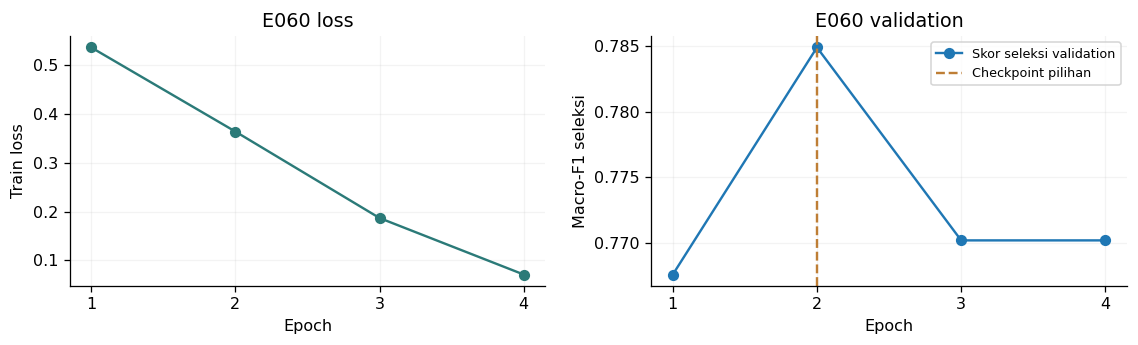

Status: completed test. Epoch yang dijalankan dan epoch checkpoint terpilih dibedakan.


In [34]:
describe_run('E060')

,Split,Tugas,Policy,macro_precision,macro_recall,macro_f1,accuracy
0,validation,appropriate,raw,0.790201,0.782253,0.784890,0.791045
1,test,appropriate,raw,0.816750,0.810010,0.812547,0.817910


,Split,Task,label,precision,recall,f1,support
0,validation,appropriate,0,0.794239,0.850220,0.821277,454
1,validation,appropriate,1,0.786164,0.714286,0.748503,350
2,test,appropriate,0,0.822554,0.867133,0.844255,572
3,test,appropriate,1,0.810945,0.752887,0.780838,433


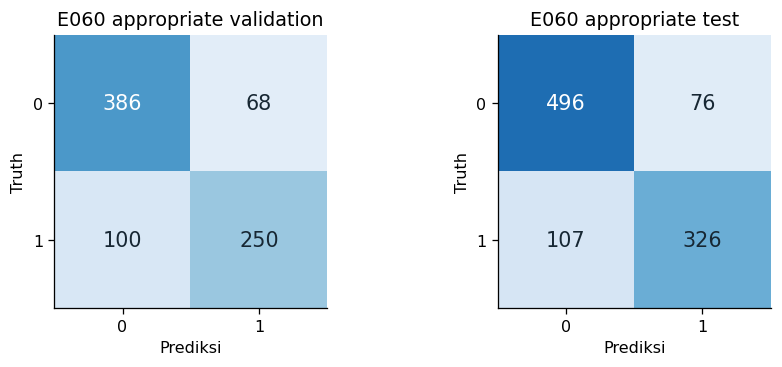

Baris=truth, kolom=prediksi. Kelas1=hate pada hate dan inappropriate pada appropriate.


In [35]:
evaluate_run('E060')

In [36]:
inspect_errors('E060')
print('Macro-F1 test inappropriate tertinggi pada paket inti teramati pada E060. Skor validation-nya lebih rendah daripada E042, sehingga keduanya tidak boleh dipertukarkan sebagai pemenang test dan kandidat validation.')

#### E060 appropriate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
7,10030062560388920.jpeg,1,0,false negative
544,1003541394914516.jpeg,1,0,false negative
902,1010091771207146.jpeg,1,0,false negative
925,1018563468837560.jpeg,0,1,false positive
174,1019254657053594.jpeg,0,1,false positive
135,1035902948572129.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,275,0.792507
not hate | appropriate,572,496,0.867133
not hate | inappropriate,86,51,0.593023


E060 appropriate: FP=76, FN=107, recall kelas1=0.7529.
Macro-F1 validation=0.7849, test=0.8125, paper=0.809, delta=+0.35 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.
Macro-F1 test inappropriate tertinggi pada paket inti teramati pada E060. Skor validation-nya lebih rendah daripada E042, sehingga keduanya tidak boleh dipertukarkan sebagai pemenang test dan kandidat validation.


### E101 Multitask teks

Satu training menghasilkan dua tugas. Checkpoint dipilih dari rata-rata metrik validation kedua tugas. Raw dan constrained inappropriate disimpan terpisah.

,ID,Run ID,Kind,Task,Batch,Akumulasi,Epoch jalan,Epoch dipilih,Config SHA256
0,E101,RQ4__text__-__IndoBERTweet__Caption+OCR+Topic__both__c53b3ac79c1b,text,both,1,8,5,5,5468f4aefcb59ff27b77d996dd62a84f234445c94d826a212db6f2ca4cf4fb2b


,text.id,text.revision
0,indolem/indobertweet-base-uncased,32e28c05b47e33b6675d2670a1745c50a65e987a


,epoch,train_loss,selection_macro_f1,appropriate_macro_f1,hate_macro_f1,appropriate_constrained_macro_f1
0,1,0.515907,0.767624,0.750660,0.784231,0.751017
1,2,0.399049,0.786434,0.762661,0.807175,0.765692
2,3,0.296598,0.793027,0.778904,0.807151,0.778904
3,4,0.192983,0.787882,0.772428,0.803337,0.772428
4,5,0.136849,0.795733,0.779749,0.811717,0.779749


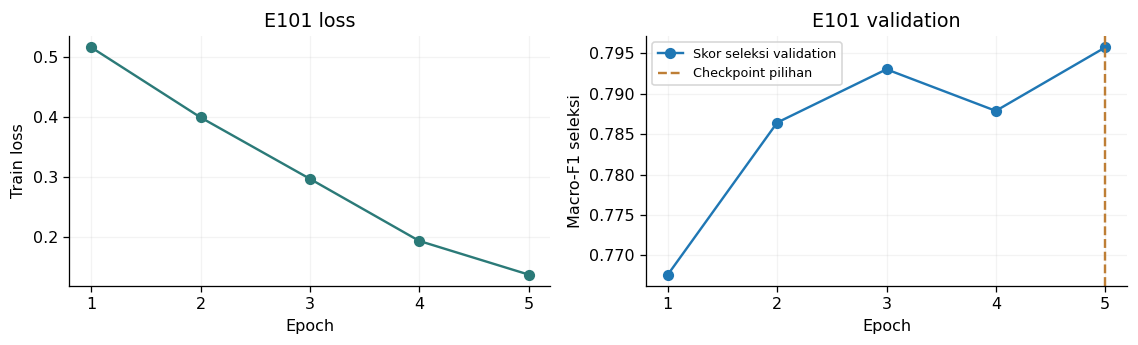

Status: completed test. Epoch yang dijalankan dan epoch checkpoint terpilih dibedakan.


In [37]:
describe_run('E101')

,Split,Tugas,Policy,macro_precision,macro_recall,macro_f1,accuracy
0,validation,hate,raw,0.826480,0.801898,0.811717,0.837065
1,test,hate,raw,0.812307,0.798315,0.804340,0.826866
2,validation,appropriate,constrained,0.788505,0.776331,0.779749,0.787313
3,test,appropriate,constrained,0.802459,0.795527,0.798065,0.803980
4,test tambahan,appropriate,raw,0.803612,0.796401,0.799020,0.804975


,Split,Task,label,precision,recall,f1,support
0,validation,hate,0,0.852113,0.911488,0.880801,531
1,validation,hate,1,0.800847,0.692308,0.742633,273
2,test,hate,0,0.851744,0.890578,0.870728,658
3,test,hate,1,0.772871,0.706052,0.737952,347
4,validation,appropriate,0,0.783567,0.861233,0.820567,454
5,validation,appropriate,1,0.793443,0.691429,0.738931,350
6,test,appropriate,0,0.809917,0.856643,0.832625,572
7,test,appropriate,1,0.795000,0.734411,0.763505,433


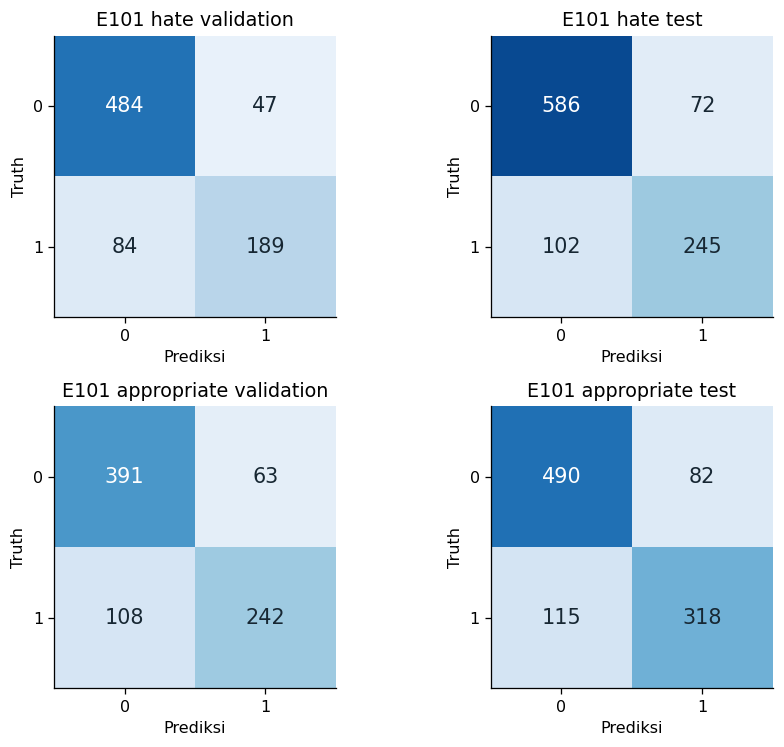

Baris=truth, kolom=prediksi. Kelas1=hate pada hate dan inappropriate pada appropriate.


In [38]:
evaluate_run('E101')

In [39]:
inspect_errors('E101')
print('Satu training menghasilkan dua tugas. Checkpoint dipilih dari rata-rata metrik validation kedua tugas. Raw dan constrained inappropriate disimpan terpisah.')

#### E101 hate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
1496,1001507855343505.jpeg,1,0,false negative
14,10030062560388920.jpeg,1,0,false negative
1804,1010091771207146.jpeg,1,0,false negative
1850,1018563468837560.jpeg,0,1,false positive
348,1019254657053594.jpeg,0,1,false positive
1960,1030872669007324.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,245,0.706052
not hate | appropriate,572,518,0.905594
not hate | inappropriate,86,68,0.790698


E101 hate: FP=72, FN=102, recall kelas1=0.7061.
Macro-F1 validation=0.8117, test=0.8043, paper=0.811, delta=-0.67 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.


#### E101 appropriate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
1497,1001507855343505.jpeg,1,0,false negative
15,10030062560388920.jpeg,1,0,false negative
1089,1003541394914516.jpeg,1,0,false negative
87,1018494587129601.jpeg,0,1,false positive
1851,1018563468837560.jpeg,0,1,false positive
349,1019254657053594.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,271,0.780980
not hate | appropriate,572,490,0.856643
not hate | inappropriate,86,47,0.546512


E101 appropriate: FP=82, FN=115, recall kelas1=0.7344.
Macro-F1 validation=0.7797, test=0.7981, paper=0.815, delta=-1.69 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.
Satu training menghasilkan dua tugas. Checkpoint dipilih dari rata-rata metrik validation kedua tugas. Raw dan constrained inappropriate disimpan terpisah.


### E110 Multitask multimodal

Satu training menghasilkan dua tugas. Epoch5 menyelesaikan training, sedangkan epoch 3 menjadi checkpoint terpilih. Multitask tidak otomatis memperbaiki kedua tugas.

,ID,Run ID,Kind,Task,Batch,Akumulasi,Epoch jalan,Epoch dipilih,Config SHA256
0,E110,RQ4__multimodal__ViT__IndoBERTweet__Caption+OCR+Topic__both__0fae85afca54,multimodal,both,1,8,5,3,a15f025642ec305d89ddc684b9ee21b66bb931a5cf281b24e4f47927f7b2e7e1


,image.id,image.revision,text.id,text.revision
0,google/vit-base-patch32-224-in21k,98cb6f7099d372694c8547bf7002289b36857dc7,indolem/indobertweet-base-uncased,32e28c05b47e33b6675d2670a1745c50a65e987a


,epoch,train_loss,selection_macro_f1,appropriate_macro_f1,hate_macro_f1,appropriate_constrained_macro_f1
0,1,0.511149,0.786212,0.768716,0.803429,0.768996
1,2,0.349336,0.800371,0.781836,0.817411,0.783331
2,3,0.223873,0.809930,0.790831,0.827653,0.792207
3,4,0.127442,0.805624,0.790199,0.819646,0.791601
4,5,0.078973,0.802489,0.782139,0.822840,0.782139


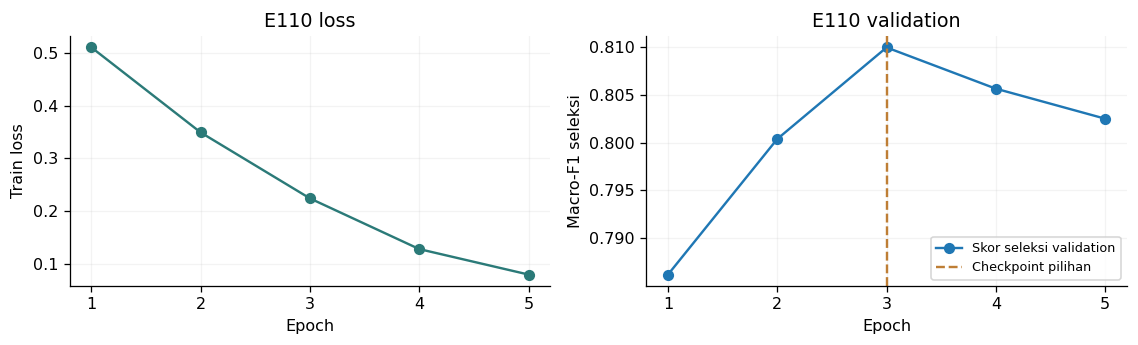

Status: completed test. Epoch yang dijalankan dan epoch checkpoint terpilih dibedakan.


In [40]:
describe_run('E110')

,Split,Tugas,Policy,macro_precision,macro_recall,macro_f1,accuracy
0,validation,hate,raw,0.834781,0.821941,0.827653,0.848259
1,test,hate,raw,0.806936,0.799440,0.802885,0.823881
2,validation,appropriate,constrained,0.798661,0.789188,0.792207,0.798507
3,test,appropriate,constrained,0.814021,0.808823,0.810884,0.815920
4,test tambahan,appropriate,raw,0.814021,0.808823,0.810884,0.815920


,Split,Task,label,precision,recall,f1,support
0,validation,hate,0,0.871143,0.903955,0.887246,531
1,validation,hate,1,0.798419,0.739927,0.768061,273
2,test,hate,0,0.856296,0.878419,0.867217,658
3,test,hate,1,0.757576,0.720461,0.738552,347
4,validation,appropriate,0,0.797959,0.861233,0.828390,454
5,validation,appropriate,1,0.799363,0.717143,0.756024,350
6,test,appropriate,0,0.824121,0.860140,0.841745,572
7,test,appropriate,1,0.803922,0.757506,0.780024,433


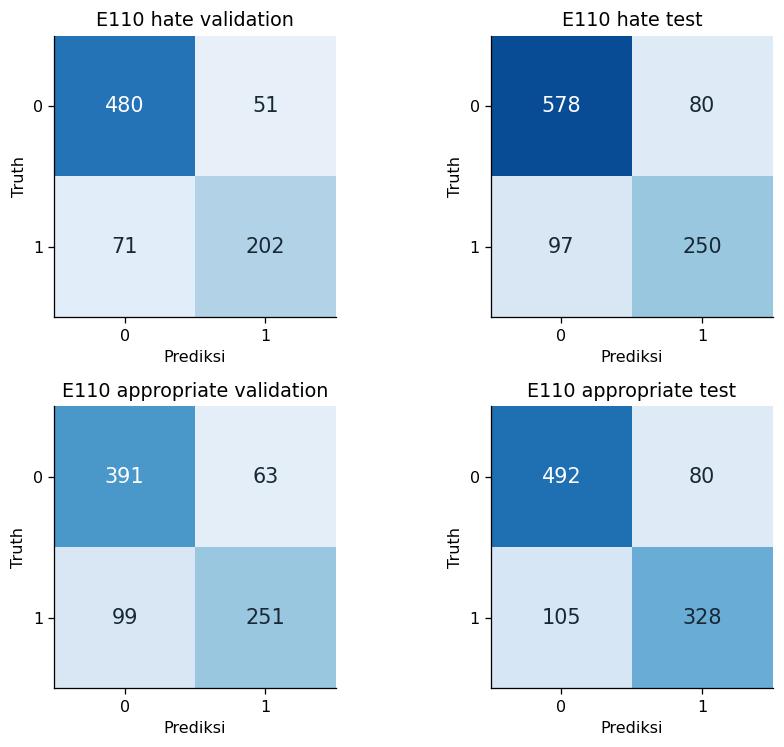

Baris=truth, kolom=prediksi. Kelas1=hate pada hate dan inappropriate pada appropriate.


In [41]:
evaluate_run('E110')

In [42]:
inspect_errors('E110')
print('Satu training menghasilkan dua tugas. Epoch5 menyelesaikan training, sedangkan epoch3 menjadi checkpoint terpilih. Multitask tidak otomatis memperbaiki kedua tugas.')

#### E110 hate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
14,10030062560388920.jpeg,1,0,false negative
1804,1010091771207146.jpeg,1,0,false negative
1278,1026441909518233.jpeg,1,0,false negative
86,1018494587129601.jpeg,0,1,false positive
1850,1018563468837560.jpeg,0,1,false positive
1960,1030872669007324.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,250,0.720461
not hate | appropriate,572,512,0.895105
not hate | inappropriate,86,66,0.767442


E110 hate: FP=80, FN=97, recall kelas1=0.7205.
Macro-F1 validation=0.8277, test=0.8029, paper=0.801, delta=+0.19 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.


#### E110 appropriate contoh kesalahan

,image_path,truth,evaluated_prediction,Jenis
15,10030062560388920.jpeg,1,0,false negative
1089,1003541394914516.jpeg,1,0,false negative
1805,1010091771207146.jpeg,1,0,false negative
87,1018494587129601.jpeg,0,1,false positive
1851,1018563468837560.jpeg,0,1,false positive
349,1019254657053594.jpeg,0,1,false positive


,Jumlah,Benar,Proporsi_benar
joint_label,,,
hate | inappropriate,347,278,0.801153
not hate | appropriate,572,492,0.860140
not hate | inappropriate,86,50,0.581395


E110 appropriate: FP=80, FN=105, recall kelas1=0.7575.
Macro-F1 validation=0.7922, test=0.8109, paper=0.803, delta=+0.79 pp.
Contoh dipilih deterministik untuk pelacakan, bukan sampel prevalensi penyebab kesalahan.
Satu training menghasilkan dua tugas. Epoch5 menyelesaikan training, sedangkan epoch3 menjadi checkpoint terpilih. Multitask tidak otomatis memperbaiki kedua tugas.


## Supervised historis di luar paket inti
SwinV2 E001 dan E002 berasal dari antrean historis yang lebih luas. E001 mempunyai hasil test;
E002 menyimpan proses parsial. Hasil tambahan dipertahankan agar seluruh progres dapat dilacak,
tanpa mengubah definisi paket inti 8 konfigurasi / 10 hasil dan tanpa menjadikan proses parsial sebagai
hasil test. Penyebutan epoch parsial tidak menjamin run tersebut layak dilanjutkan tanpa preflight baru.

### E001 completed_test_historical_outside_core

,Run ID,Task,Encoder gambar,Batch,Akumulasi,Status
0,RQ2__image__SwinV2__-__-__hate__7bfd12deea55,hate,SwinV2,2,4,completed_test_historical_outside_core


,epoch,train_loss,selection_macro_f1,hate_macro_f1
0,1,0.6425218472457778,0.5011797441224302,0.5011797441224302
1,2,0.5962136327320919,0.6288967104236217,0.6288967104236217
2,3,0.5400208599781983,0.615210377934295,0.615210377934295
3,4,0.504986793947984,0.6240996172150767,0.6240996172150767


Status test: ada
Catatan: Historical SwinV2 image-only hate model completed test before the core scope was narrowed. Its test macro-F1 is 0.6269662, versus core ViT E005 0.6408129. This extra result is reported separately, not substituted into the eight-core table.


,label,precision,recall,f1,support,Split,Tugas
0,0,0.757028,0.709981,0.732750,531,validation,hate
1,1,0.496732,0.556777,0.525043,273,validation,hate


,image_path,truth,prediction
345,10007163152657541.jpeg,0,1
161,10028998933828616.jpeg,1,0
364,1003786335117124.jpeg,0,1
715,1007367488109132.jpeg,0,1
38,1011379457691145.jpeg,0,1
454,1014177377411353.jpeg,1,0


,label,precision,recall,f1,support,Split,Tugas
0,0,0.754125,0.694529,0.723101,658,test,hate
1,1,0.496241,0.570605,0.530831,347,test,hate


,image_path,truth,prediction
748,1001507855343505.jpeg,1,0
7,10030062560388920.jpeg,1,0
938,1005306118298479.jpeg,0,1
993,1009879063039334.jpeg,0,1
925,1018563468837560.jpeg,0,1
570,1020425740269819.jpeg,0,1


,Split,Task,macro_precision,macro_recall,macro_f1,accuracy
0,validation,hate,0.626880,0.633379,0.628897,0.657960
1,test,hate,0.625183,0.632567,0.626966,0.651741


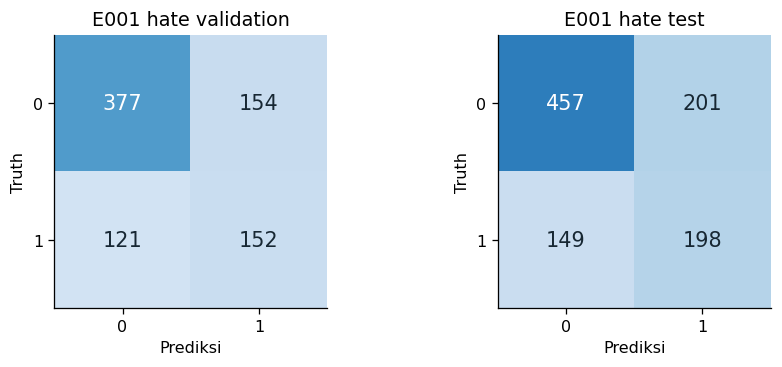

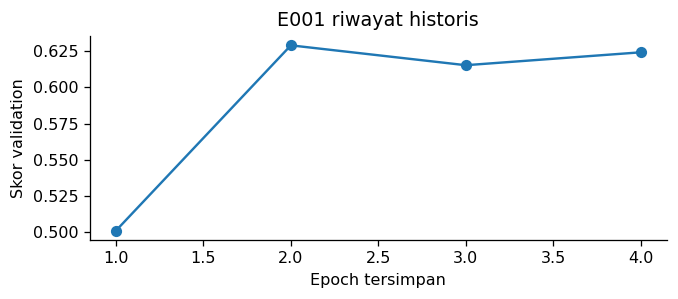

### E002 partial_deferred_scope_no_test

,Run ID,Task,Encoder gambar,Batch,Akumulasi,Status
0,RQ2__image__SwinV2__-__-__appropriate__490779049ff8,appropriate,SwinV2,2,4,partial_deferred_scope_no_test


,epoch,train_loss,selection_macro_f1,appropriate_macro_f1
0,1,0.6853848611744725,0.5346542686983756,0.5346542686983756
1,2,0.6353917851042659,0.6193252967012428,0.6193252967012428
2,3,0.5868054110540614,0.6088677027556484,0.6088677027556484


Status test: belum dievaluasi
Catatan: SwinV2 inappropriate was deferred when scope changed. Three epochs are recorded; best validation macro-F1 0.6193253 at epoch 2. No completed result or test metric exists. Do not treat this as CUDA OOM or finished training.


,label,precision,recall,f1,support,Split,Tugas
0,0,0.680288,0.623348,0.650575,454,validation,appropriate
1,1,0.559278,0.620000,0.588076,350,validation,appropriate


,image_path,truth,prediction
345,10007163152657541.jpeg,0,1
161,10028998933828616.jpeg,1,0
364,1003786335117124.jpeg,0,1
715,1007367488109132.jpeg,0,1
38,1011379457691145.jpeg,0,1
46,1011980094297748.jpeg,0,1


,Split,Task,macro_precision,macro_recall,macro_f1,accuracy
0,validation,appropriate,0.619783,0.621674,0.619325,0.621891


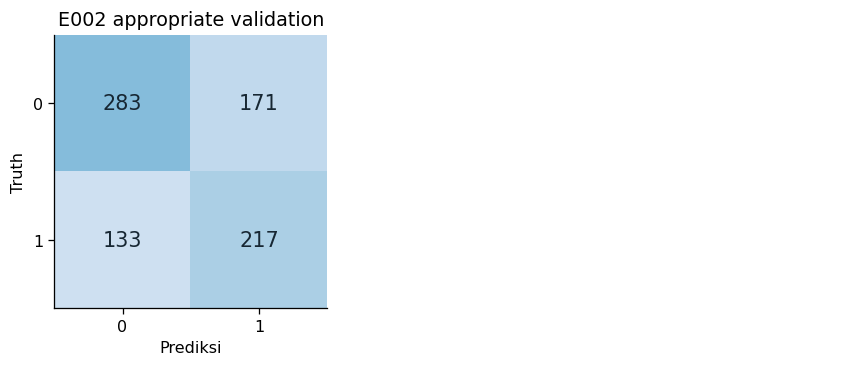

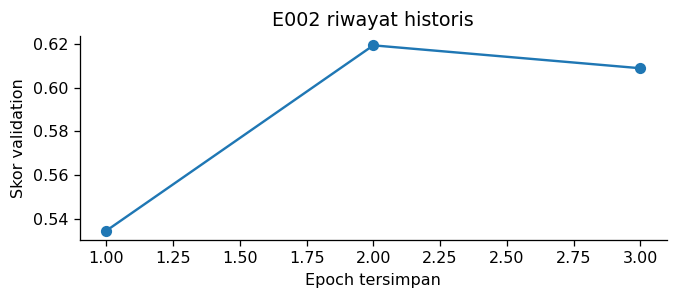

In [43]:
for extra in inventory['supplementary_supervised']:
    display(Markdown('### '+extra['id']+' '+extra['status']))
    cfg=extra['config']
    display(pd.DataFrame([{'Run ID':extra.get('run_id',''),'Task':cfg['task'],'Encoder gambar':cfg['image'],
        'Batch':cfg['batch_size'],'Akumulasi':cfg['gradient_accumulation'],'Status':extra['status']}]))
    display(pd.DataFrame(extra.get('history',[])))
    print('Status test:', 'ada' if extra.get('test_metrics') else 'belum dievaluasi')
    print('Catatan:',extra.get('insight',extra.get('note','Di luar paket inti.')))
    panels=[];extra_metrics=[]
    for split in ['validation','test']:
        pred_path=extra.get('files',{}).get(split+'_predictions')
        if not pred_path:continue
        frame=read_csv(pred_path)
        for task,group in frame.groupby('task'):
            result=manual_metrics(group.truth,group.prediction)
            expected=extra[split+'_metrics'][task]
            for key in ['macro_precision','macro_recall','macro_f1','accuracy']:
                assert abs(result[key]-expected[key])<1e-12
            extra_metrics.append({'Split':split,'Task':task,**{key:result[key] for key in ['macro_precision','macro_recall','macro_f1','accuracy']}})
            display(pd.DataFrame(result['per_class']).assign(Split=split,Tugas=task))
            panels.append((extra['id']+' '+task+' '+split,result))
            errors=group[group.truth.astype(int)!=group.prediction.astype(int)].sort_values('image_path').head(6)
            display(errors[['image_path','truth','prediction']])
    display(pd.DataFrame(extra_metrics))
    if panels:plot_cm_panels(panels)
    history=pd.DataFrame(extra.get('history',[]))
    if not history.empty and 'epoch' in history:
        fig,ax=plt.subplots(figsize=(6,2.7))
        ax.plot(history.epoch.astype(int),history.selection_macro_f1.astype(float),marker='o')
        ax.set(xlabel='Epoch tersimpan',ylabel='Skor validation',title=extra['id']+' riwayat historis')
        fig.tight_layout();plt.show()

## Dampak aturan hierarki multitask
Aturan hate mengimplikasikan inappropriate meningkatkan konsistensi label, tetapi belum tentu
meningkatkan Macro-F1. Di bawah ini setiap perubahan prediksi ditelusuri langsung dari kolom raw
dan constrained pada validation serta test. Probabilitas head bukan probabilitas yang telah
dikalibrasi dan tidak digunakan untuk mengganti threshold.

In [44]:
hierarchy=[]
for identifier in ['E101','E110']:
    for split in ['validation','test']:
        frame=read_csv(f'runs/{identifier}/{split}_predictions.csv')
        a=frame[frame.task=='appropriate'].set_index('image_path')
        h=frame[frame.task=='hate'].set_index('image_path').loc[a.index]
        expected=np.maximum(a.prediction.astype(int),h.prediction.astype(int))
        assert np.array_equal(expected,a.prediction_constrained.astype(int))
        raw=manual_metrics(a.truth,a.prediction);constrained=manual_metrics(a.truth,a.prediction_constrained)
        changed=a.prediction.astype(int)!=a.prediction_constrained.astype(int)
        improved=changed&(a.truth.astype(int)==a.prediction_constrained.astype(int))
        worsened=changed&(a.truth.astype(int)==a.prediction.astype(int))
        hierarchy.append({'ID':identifier,'Split':split,'Raw F1':raw['macro_f1'],'Constrained F1':constrained['macro_f1'],
          'Berubah':int(changed.sum()),'Salah menjadi benar':int(improved.sum()),'Benar menjadi salah':int(worsened.sum())})
        if changed.any():display(a.loc[changed,['truth','prediction','prediction_constrained']])
display(pd.DataFrame(hierarchy))
print('Interpretasi: relasi hierarki dan skor per kelas mengukur hal berbeda. E101 test mengubah satu prediksi benar menjadi salah.')

,truth,prediction,prediction_constrained
image_path,,,
201357395703266.jpeg,0,0,1


,truth,prediction,prediction_constrained
image_path,,,
236599585978672.jpeg,1,0,1


,ID,Split,Raw F1,Constrained F1,Berubah,Salah menjadi benar,Benar menjadi salah
0,E101,validation,0.779749,0.779749,0,0,0
1,E101,test,0.799020,0.798065,1,0,1
2,E110,validation,0.790831,0.792207,1,1,0
3,E110,test,0.810884,0.810884,0,0,0


Interpretasi: relasi hierarki dan skor per kelas mengukur hal berbeda. E101 test mengubah satu prediksi benar menjadi salah.


## Perbandingan berpasangan modalitas dan multitask
Perbandingan memakai ID test yang sama. A benar saja dan B benar saja menunjukkan pertukaran
kesalahan, sedangkan keduanya salah menunjukkan sasaran audit manual bersama. Selisih Macro-F1
bersifat deskriptif pada seed 42. Notebook tidak mengklaim signifikansi atau penyebab semantik.

,A,B,Task,Keduanya benar,A benar saja,B benar saja,Keduanya salah,Delta B pp
0,E041,E059,hate,809,22,19,155,-0.151451
1,E042,E060,appropriate,789,22,33,161,1.413371
2,E041,E101,hate,794,37,37,137,-0.146018
3,E042,E101,appropriate,765,46,43,151,-0.034775
4,E059,E110,hate,793,35,35,142,-0.140099
5,E060,E110,appropriate,777,45,43,140,-0.166239


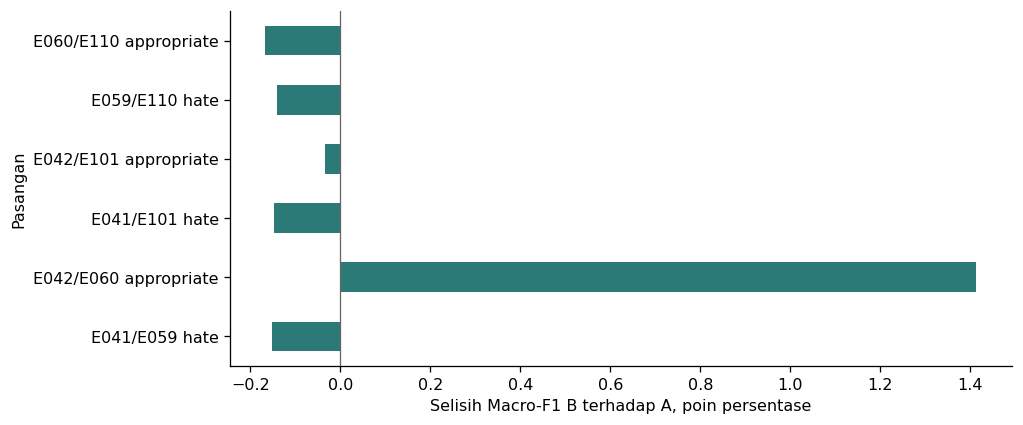

Fusi E059 vs E041 hate: -0.1514505561567292 pp. Fusi E060 vs E042 inappropriate: 1.4133709263224215 pp.


In [45]:
pairs=[]
for reference in facts['comparisons']:
    task=reference['task'];a=reference['a'];b=reference['b']
    ma,fa=RUN_RESULTS[(a,task,'test')];mb,fb=RUN_RESULTS[(b,task,'test')]
    joined=fa[['image_path','truth','evaluated_prediction']].merge(fb[['image_path','truth','evaluated_prediction']],on='image_path',suffixes=('_a','_b'),validate='one_to_one')
    assert (joined.truth_a==joined.truth_b).all() and len(joined)==1005
    ca=joined.truth_a.astype(int)==joined.evaluated_prediction_a;cb=joined.truth_b.astype(int)==joined.evaluated_prediction_b
    row={'A':a,'B':b,'Task':task,'Keduanya benar':int((ca&cb).sum()),'A benar saja':int((ca&~cb).sum()),
      'B benar saja':int((~ca&cb).sum()),'Keduanya salah':int((~ca&~cb).sum()),'Delta B pp':100*(mb['macro_f1']-ma['macro_f1'])}
    assert row['A benar saja']==reference['a_only_correct'] and row['B benar saja']==reference['b_only_correct']
    pairs.append(row)
display(pd.DataFrame(pairs))
ax=pd.DataFrame(pairs).assign(Pasangan=lambda d:d.A+'/'+d.B+' '+d.Task).plot.barh(x='Pasangan',y='Delta B pp',color='#2B7A78',legend=False,figsize=(9,3.8))
ax.axvline(0,color='#666',lw=.8);ax.set_xlabel('Selisih Macro-F1 B terhadap A, poin persentase')
plt.tight_layout();plt.show()
print('Fusi E059 vs E041 hate:',pairs[0]['Delta B pp'],'pp. Fusi E060 vs E042 inappropriate:',pairs[1]['Delta B pp'],'pp.')

## Kandidat berdasarkan validation
Pemilihan checkpoint di dalam setiap run tetap mengikuti kriteria yang sudah ditetapkan.
Sebagai interpretasi pengumpulan, kandidat per tugas dibandingkan dari validation pada checkpoint
yang sudah terpilih. Test dilaporkan sesudahnya. Ini bukan klaim kandidat yang stabil lintas seed,
dan bukan kebijakan global yang diklaim telah dikunci sebelum semua run historis.

In [46]:
rankings=[]
for outcome in facts['outcomes']:
    validation,_=RUN_RESULTS[(outcome['id'],outcome['task'],'validation')]
    test,_=RUN_RESULTS[(outcome['id'],outcome['task'],'test')]
    rankings.append({'ID':outcome['id'],'Task':outcome['task'],'Validation F1':validation['macro_f1'],'Test F1':test['macro_f1']})
rankings=pd.DataFrame(rankings)
for task,group in rankings.groupby('Task'):
    ranked=group.sort_values('Validation F1',ascending=False).reset_index(drop=True)
    display(ranked)
    candidate=ranked.iloc[0];margin=100*(ranked.iloc[0]['Validation F1']-ranked.iloc[1]['Validation F1'])
    assert candidate.ID==facts['validation_candidates'][task]['id']
    print(f"Kandidat {task}: {candidate.ID}, margin validation {margin:.5f} pp.")
print('E059 menjadi kandidat hate. E042 menjadi kandidat inappropriate. E060 test tertinggi tidak menggantikan keputusan berbasis validation.')

,ID,Task,Validation F1,Test F1
0,E042,appropriate,0.792355,0.798413
1,E110,appropriate,0.792207,0.810884
2,E060,appropriate,0.784890,0.812547
3,E101,appropriate,0.779749,0.798065
4,E006,appropriate,0.634784,0.631455


Kandidat appropriate: E042, margin validation 0.01484 pp.


,ID,Task,Validation F1,Test F1
0,E059,hate,0.829291,0.804286
1,E110,hate,0.827653,0.802885
2,E041,hate,0.820765,0.805800
3,E101,hate,0.811717,0.804340
4,E005,hate,0.640726,0.640813


Kandidat hate: E059, margin validation 0.16377 pp.
E059 menjadi kandidat hate. E042 menjadi kandidat inappropriate. E060 test tertinggi tidak menggantikan keputusan berbasis validation.


## Perbandingan dengan paper
Macro-F1 paper merupakan acuan pada kondisi terpilih. Selisih poin persentase adalah 100 kali
skor reproduksi dikurangi skor paper. Perbedaan batch, validation, checkpoint ViT, pooling,
dan tuning lambda membatasi klaim reproduksi numerik identik. Angka lebih tinggi pada satu run
tidak membuktikan keunggulan yang konsisten.

,id,task,policy,macro_f1,paper_macro_f1,delta_percentage_points
0,E005,hate,raw,0.640813,0.630,1.081288
1,E006,appropriate,raw,0.631455,0.630,0.145491
2,E041,hate,raw,0.805800,0.800,0.580012
3,E042,appropriate,raw,0.798413,0.788,1.041311
4,E059,hate,raw,0.804286,0.820,-1.571438
5,E060,appropriate,raw,0.812547,0.809,0.354682
6,E101,hate,raw,0.804340,0.811,-0.666005
7,E101,appropriate,constrained,0.798065,0.815,-1.693464
8,E110,hate,raw,0.802885,0.801,0.188462
9,E110,appropriate,constrained,0.810884,0.803,0.788443


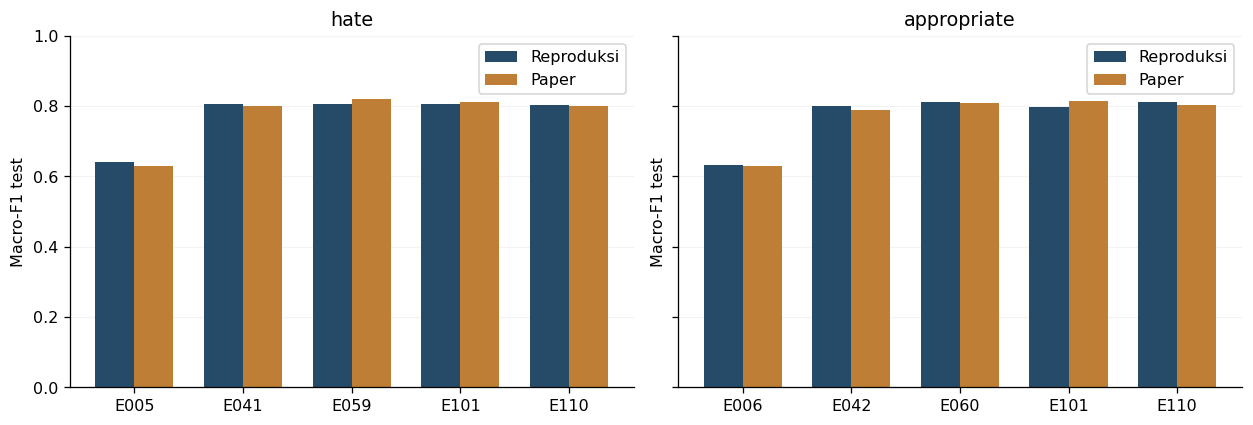

In [47]:
comparison=core[['id','task','policy','macro_f1','paper_macro_f1','delta_percentage_points']].copy()
assert np.allclose(100*(comparison.macro_f1-comparison.paper_macro_f1),comparison.delta_percentage_points,atol=1e-12,rtol=0)
display(comparison)
fig,axes=plt.subplots(1,2,figsize=(11,3.8),sharey=True)
for ax,task in zip(axes,['hate','appropriate']):
    subset=comparison[comparison.task==task];x=np.arange(len(subset));w=.36
    ax.bar(x-w/2,subset.macro_f1,w,label='Reproduksi',color='#264B68')
    ax.bar(x+w/2,subset.paper_macro_f1,w,label='Paper',color='#BE7E35')
    ax.set(xticks=x,xticklabels=subset.id,ylim=(0,1),title=task,ylabel='Macro-F1 test')
    ax.legend();ax.grid(axis='y',alpha=.15);ax.set_axisbelow(True)
fig.tight_layout();plt.show()

## Kegagalan percobaan dan keputusan penanganan
Riwayat CUDA out of memory, percobaan inferensi RQ3 historis, dan run parsial adalah bagian progres yang relevan.
Statusnya dipisahkan dari hasil final. Isi error yang ditampilkan berasal dari bukti yang sudah
disaring dalam inventory, tanpa kredensial. Tidak ada kegagalan yang diperbaiki dengan mengubah
test atau mengganti metode secara diam-diam.

In [48]:
display(pd.DataFrame(inventory.get('failed_attempts',[])))
display(pd.DataFrame(inventory.get('rq3_attempts',[])))
print('OOM historis ditangani melalui penyesuaian microbatch dan eksekusi pada lab; konfigurasi run baru dicatat terpisah.')
print('Percobaan RQ3 yang gagal/tidak lengkap tidak menghasilkan skor test yang dapat dipakai untuk klaim supervised versus MLLM.')
print('E002 parsial berada di luar paket aktif; tidak dipromosikan menjadi eksperimen selesai.')

,id,condition,status,stage,error_type,error_message,source,final_successful_replacement,test_metrics,insight
0,E059_local_original,E059,failed_cuda_oom,backward,RuntimeError,RuntimeError: CUDA error: out of memory,evidence/failed_attempts/E059_local_original.log,E059_lab_2026-10-28,None,A one-batch calibration does not guarantee memory for a full epoch. Historical local training fa...
1,E101_local_original,E101,failed_cuda_oom,backward,RuntimeError,RuntimeError: CUDA error: out of memory,evidence/failed_attempts/E101_local_original.log,E101_lab_2026-10-28,None,A one-batch calibration does not guarantee memory for a full epoch. Historical local training fa...


,model,scope,run,status,request_count,recorded_prediction_rows,valid_label_rows,raw_response_attempts,error_types,completion,files,research_test_result,insight
0,LLaVA OneVision 0.5B,full,full__d8cfc2726036,incomplete_partial_not_research_result,1005,2,1,2,{'ValueError': 1},"{'requested': 1005, 'recorded': 2, 'valid_labels': 1, 'new_requests': 2, 'scope': 'full', 'compl...",{'config': 'evidence/historical_rq3/RQ3__zero-shot__LLaVA_OneVision_0.5B__-__Image__hate/full__d...,False,Historical local smoke/partial generation only. Responses contain errors or invalid label output...
1,LLaVA OneVision 0.5B,smoke,smoke__6a3ae35e666b,smoke_complete_not_research_result,1,1,1,2,{'ModuleNotFoundError': 1},"{'requested': 1, 'recorded': 1, 'valid_labels': 1, 'new_requests': 1, 'scope': 'smoke', 'complet...",{'config': 'evidence/historical_rq3/RQ3__zero-shot__LLaVA_OneVision_0.5B__-__Image__hate/smoke__...,False,Historical local smoke/partial generation only. Responses contain errors or invalid label output...
2,LLaVA OneVision 0.5B,smoke,smoke__cb5abfb7aee3,incomplete_partial_not_research_result,3,3,2,3,{},"{'requested': 3, 'recorded': 3, 'valid_labels': 2, 'new_requests': 3, 'scope': 'smoke', 'complet...",{'config': 'evidence/historical_rq3/RQ3__zero-shot__LLaVA_OneVision_0.5B__-__Image__hate/smoke__...,False,Historical local smoke/partial generation only. Responses contain errors or invalid label output...
3,Qwen2-VL 2B,smoke,smoke__8e71801efce7,prepared_without_response_evidence,3,0,0,0,{},None,{'config': 'evidence/historical_rq3/RQ3__zero-shot__Qwen2-VL_2B__-__Image__hate/smoke__8e71801ef...,False,Only configuration/requests exist; no completion or response artifact supports a model score or ...
4,Qwen2-VL 2B,smoke,smoke__aec1c2daa729,prepared_without_response_evidence,1,0,0,0,{},None,{'config': 'evidence/historical_rq3/RQ3__zero-shot__Qwen2-VL_2B__-__Image__hate/smoke__aec1c2daa...,False,Only configuration/requests exist; no completion or response artifact supports a model score or ...


OOM historis ditangani melalui penyesuaian microbatch dan eksekusi pada lab; konfigurasi run baru dicatat terpisah.
Percobaan RQ3 yang gagal/tidak lengkap tidak menghasilkan skor test yang dapat dipakai untuk klaim supervised versus MLLM.
E002 parsial berada di luar paket aktif; tidak dipromosikan menjadi eksperimen selesai.


## Kalibrasi dan batas sumber daya
Smoke test satu batch serta kalibrasi VRAM/checkpoint menunjukkan kesiapan tahap tertentu,
bukan hasil training penuh. Penggunaan folder kelompok, tmux, batas ruang, dan antrean berurutan
mendukung keberlangsungan proses pada akun lab bersama. Server tidak dipasangi agentic tools.

In [49]:
display(pd.DataFrame(inventory.get('calibrations',[])))
display(pd.DataFrame(inventory.get('runtime_checks',[])))
lab_calibration_rows=[]
for identifier in ['E059','E101','E006','E110']:
    calibration=read_json(f'evidence/lab_calibrations/{identifier}.json')
    assert calibration['passed'] is True and calibration['id']==identifier
    assert calibration['optimizer_steps']==1 and calibration['accumulation_steps']==8
    assert calibration['checkpoint_atomic_save_and_load'] is True
    assert calibration['test_evaluated'] is False
    assert calibration['input_length']==(None if identifier=='E006' else 256)
    assert calibration['seconds']>0 and calibration['peak_allocated_mib']>0
    lab_calibration_rows.append({'ID':identifier,'Lulus':True,'GPU':calibration['gpu_name'],
      'Panjang teks':calibration['input_length'],'Langkah optimizer':calibration['optimizer_steps'],
      'Akumulasi':calibration['accumulation_steps'],'VRAM allocated MiB':calibration['peak_allocated_mib'],
      'VRAM reserved MiB':calibration['peak_reserved_mib'],'Durasi detik':calibration['seconds'],
      'Simpan dan muat checkpoint':calibration['checkpoint_atomic_save_and_load'],'Test dievaluasi':False})
display(pd.DataFrame(lab_calibration_rows))
CHECKS['lab_calibrations_checked']=len(lab_calibration_rows)
print('Empat catatan kalibrasi lab ini berasal dari artefak yang diambil melalui SSH. Notebook hanya membaca dan memeriksanya, tanpa menjalankan ulang optimizer.')
print('E006 menerima gambar saja, sehingga panjang teks tidak berlaku. Tiga kondisi teks/fusi memakai panjang input 256 saat kalibrasi.')
print('Training inti berjalan berurutan. Microbatch1/akumulasi8 pada lab menggunakan FP32.')
print('Cadangan operasional laptop: C minimal10GiB dan D minimal12GiB, di luar kebutuhan puncak checkpoint.')
print('Waktu atau VRAM smoke test tidak diekstrapolasi sebagai durasi atau biaya full training.')

,kind,success,gpu,loss,seconds_one_step,peak_allocated_mib,peak_reserved_mib,test_evaluated,id,source,evaluation,insight,execution_observed_directly,provenance,verification_path,completed_utc
0,one_batch_smoke_only,True,Tesla T4,0.749701,2.570613,1690.817383,1916.0,False,colab_vit_received_2026-10-18,evidence/calibrations/colab_vit_received_2026-10-18.json,one_batch_calibration,"One successful forward/backward step checks feasibility only; loss, time and VRAM are not valida...",False,"User-supplied Colab artifact, schema and revisions independently checked, execution not directly...",evidence/calibrations/colab_vit_received_2026-10-18_verification.json,NaN
1,real_pretrained_one_batch_calibration,True,NVIDIA GeForce RTX 3050 6GB Laptop GPU,0.737444,5.801300,1698.535156,1916.0,False,local_vit_2026-10-23,evidence/calibrations/local_vit_2026-10-23.json,one_batch_calibration,"One successful forward/backward step checks feasibility only; loss, time and VRAM are not valida...",NaN,NaN,NaN,2026-10-23T14:10:37.363228+00:00
2,real_pretrained_one_batch_calibration,True,NVIDIA GeForce RTX 3050 6GB Laptop GPU,0.590871,7.729048,3839.673828,4238.0,False,local_fusion_E059_2026-10-23,evidence/calibrations/local_fusion_E059_2026-10-23.json,one_batch_calibration,"One successful forward/backward step checks feasibility only; loss, time and VRAM are not valida...",NaN,NaN,NaN,2026-10-23T16:31:12.658681+00:00


,id,data,source,insight
0,post_cleanup_cpu,"{'passed': True, 'mode': 'cpu', 'torch': '2.6.0+cpu', 'device': 'cpu', 'forward_backward': True,...",evidence/runtime_checks/storage_runtime_cpu.json,Forward/backward dependency check after cleanup; not a separate paper experiment.
1,post_cleanup_gpu,"{'passed': True, 'mode': 'gpu', 'torch': '2.6.0+cu124', 'device': 'cuda', 'forward_backward': Tr...",evidence/runtime_checks/storage_runtime_gpu.json,Forward/backward dependency check after cleanup; not a separate paper experiment.


,ID,Lulus,GPU,Panjang teks,Langkah optimizer,Akumulasi,VRAM allocated MiB,VRAM reserved MiB,Durasi detik,Simpan dan muat checkpoint,Test dievaluasi
0,E059,True,NVIDIA GeForce RTX 3060,256.0,1,8,3839.231445,4330.0,47.982785,True,False
1,E101,True,NVIDIA GeForce RTX 3060,256.0,1,8,2143.040039,2412.0,20.381180,True,False
2,E006,True,NVIDIA GeForce RTX 3060,NaN,1,8,1697.596680,1914.0,25.176419,True,False
3,E110,True,NVIDIA GeForce RTX 3060,256.0,1,8,3839.263184,4330.0,39.842441,True,False


Empat catatan kalibrasi lab ini berasal dari artefak yang diambil melalui SSH. Notebook hanya membaca dan memeriksanya, tanpa menjalankan ulang optimizer.
E006 menerima gambar saja, sehingga panjang teks tidak berlaku. Tiga kondisi teks/fusi memakai panjang input 256 saat kalibrasi.
Training inti berjalan berurutan. Microbatch1/akumulasi8 pada lab menggunakan FP32.
Cadangan operasional laptop: C minimal10GiB dan D minimal12GiB, di luar kebutuhan puncak checkpoint.
Waktu atau VRAM smoke test tidak diekstrapolasi sebagai durasi atau biaya full training.


## Sintesis hasil dan batas interpretasi
Pada seed 42, fusi tidak memberi perbaikan yang seragam: hate sedikit turun terhadap teks,
sedangkan inappropriate meningkat. Multitask juga belum memperbaiki kedua tugas secara konsisten.
Kelompok not hate tetapi inappropriate berisi 86 meme test, sehingga relasi hierarki hate tidak
mencakup seluruh tantangan kelayakan.

Hasil kuantitatif belum membuktikan penyebab seperti sarkasme, kualitas OCR, konteks budaya, atau
ambiguitas anotasi. Contoh error dan kandidat pHash memerlukan review manual dengan protokol
anotasi. Variasi lintas seed, evaluasi tanpa topik anotasi, dan penanganan duplikat memerlukan
rancangan lanjutan. RQ3/API, grid penuh, dan novelty tidak dinyatakan selesai.

In [50]:
subgroups=[]
for identifier in ['E042','E060','E101','E110']:
    _,frame=RUN_RESULTS[(identifier,'appropriate','test')]
    joined=frame.merge(meta[['image_path','joint_label']],on='image_path',validate='one_to_one')
    group=joined[joined.joint_label=='not hate | inappropriate']
    assert len(group)==86
    correct=int((group.truth.astype(int)==group.evaluated_prediction).sum())
    subgroups.append({'ID':identifier,'Kelompok':'not hate dan inappropriate','Jumlah':86,'Benar':correct,'Proporsi benar':correct/86})
display(pd.DataFrame(subgroups))
current_limitations=[
 'Paket inti delapan konfigurasi dari 90 supervised. RQ3/API dan pengembangan metode baru berada di luar target aktif.',
 'Satu seed dan satu pembagian validation. Variasi lintas seed, interval kepercayaan, dan klaim signifikansi belum tersedia.',
 'Batch, validation, early stopping, checkpoint ViT dan pooling berbeda atau perlu klarifikasi terhadap implementasi penulis.',
 'Topik anotasi rilis adalah privileged input. Sistem yang harus memprediksi topik meme baru belum dievaluasi.',
 'Dua kelompok gambar identik melintasi train/test resmi. Screening pHash 197 kandidat telah dilakukan, tetapi review manual belum selesai.',
 'Error kuantitatif belum menetapkan penyebab sarkasme, OCR atau konteks budaya tanpa anotasi manual.',
 'Pemilihan kandidat lintas konfigurasi adalah interpretasi validation saat pengumpulan, bukan pencarian model berdasarkan test.'
]
display(pd.DataFrame({'Keterbatasan':current_limitations}))
print('Koreksi cakupan audit: pHash screening sudah dilakukan; yang belum selesai adalah review manual kandidat.')

,ID,Kelompok,Jumlah,Benar,Proporsi benar
0,E042,not hate dan inappropriate,86,48,0.558140
1,E060,not hate dan inappropriate,86,51,0.593023
2,E101,not hate dan inappropriate,86,47,0.546512
3,E110,not hate dan inappropriate,86,50,0.581395


,Keterbatasan
0,Paket inti delapan konfigurasi dari 90 supervised. RQ3/API dan pengembangan metode baru berada d...
1,"Satu seed dan satu pembagian validation. Variasi lintas seed, interval kepercayaan, dan klaim si..."
2,"Batch, validation, early stopping, checkpoint ViT dan pooling berbeda atau perlu klarifikasi ter..."
3,Topik anotasi rilis adalah privileged input. Sistem yang harus memprediksi topik meme baru belum...
4,Dua kelompok gambar identik melintasi train/test resmi. Screening pHash 197 kandidat telah dilak...
5,"Error kuantitatif belum menetapkan penyebab sarkasme, OCR atau konteks budaya tanpa anotasi manual."
6,"Pemilihan kandidat lintas konfigurasi adalah interpretasi validation saat pengumpulan, bukan pen..."


Koreksi cakupan audit: pHash screening sudah dilakukan; yang belum selesai adalah review manual kandidat.


## Backup reproduksibilitas dan rujukan
Kode, config, history, prediksi, metrik, revisi sumber, dan receipt dipertahankan terpisah dari
bobot besar. Backup utama memuat 8 best checkpoint dan 4 resume checkpoint lab yang dipecah menjadi 73 bagian.
Seluruh bagian serta berkas pendukung telah cocok checksum unduhan pada snapshot 29 Oktober.
Pembukaan CPU dan penggabungan bagian lokal telah lulus. Checksum unduh ulang 8 best checkpoint utuh
di Drive belum diperiksa pada snapshot tersebut. Resume checkpoint historis tidak dipertahankan.

Untuk mengulang analisis notebook, gunakan paket bukti lengkap dan jalankan semua sel pada Python 3.11+
dengan numpy, pandas, matplotlib, scikit-learn, dan kernel IPython. Tidak dibutuhkan GPU, bobot,
PyTorch, koneksi internet, token API, atau password server di notebook ini.

In [51]:
display(pd.DataFrame(facts['sources']))
print('DOI paper: 10.7717/peerj-cs.3736')
print('Dataset card: https://huggingface.co/datasets/aiatums/INDOMEME')
print('Publisher: https://peerj.com/articles/cs-3736/')
print('Sumber implementasi tampak pada sel model dan training, serta folder src/.')
print('Tidak ada langkah download, training, inferensi baru atau pemanggilan layanan API pada eksekusi notebook ini.')

,title,url,doi,access_note,cached_path,live_checked,license,revision
0,Pamungkas et al. 2026. Decoding hate in memes: multimodal and multitask approaches for low-resou...,https://peerj.com/articles/cs-3736/,10.7717/peerj-cs.3736,Publisher page and PDF returned HTTP 403 during final check. Primary article text cached from of...,notebooks/runs/presentasi_2026-10-24/workspace/scripts/546797c7108a/paper_text.md,NaN,NaN,NaN
1,INDOMEME dataset card,https://huggingface.co/datasets/aiatums/INDOMEME,NaN,NaN,NaN,True,CC BY 4.0,3e0cb8cae9cd726582f69afdb122163d0eab108b
2,Publisher supplementary dataset,https://dfzljdn9uc3pi.cloudfront.net/2026/cs-3736/1/INDOMEME_Dataset.zip,NaN,NaN,NaN,NaN,NaN,NaN
3,Publisher supplementary source code,https://dfzljdn9uc3pi.cloudfront.net/2026/cs-3736/1/Source_Codes.zip,NaN,NaN,NaN,NaN,NaN,NaN


DOI paper: 10.7717/peerj-cs.3736
Dataset card: https://huggingface.co/datasets/aiatums/INDOMEME
Publisher: https://peerj.com/articles/cs-3736/
Sumber implementasi tampak pada sel model dan training, serta folder src/.
Tidak ada langkah download, training, inferensi baru atau pemanggilan layanan API pada eksekusi notebook ini.


## Bukti eksekusi notebook
Sel ini hanya dapat menghasilkan keluaran setelah seluruh analisis di atas benar-benar dijalankan.
Host, waktu, jumlah hasil yang diperiksa, serta versi runtime dicatat untuk membedakan notebook
yang sekadar ditulis dari notebook yang dieksekusi. Receipt tidak memuat password atau token.

In [52]:
assert CHECKS['core_test_outcomes']==10
assert CHECKS['baseline_validation_trials']==14
assert CHECKS['lab_calibrations_checked']==4
assert CHECKS['split_ids_eight_runs_checked'] and CHECKS['metadata_rows']==5023
assert CHECKS['training_or_inference_started'] is False
finished=datetime.now(timezone.utc)
execution_receipt={'status':'all_analysis_cells_completed','executed_utc':finished.isoformat(),
 'executed_wib':finished.astimezone(timezone(timedelta(hours=7))).isoformat(),
 'hostname':socket.gethostname(),'platform':platform.platform(),'python':platform.python_version(),
 'numpy':np.__version__,'pandas':pd.__version__,'checks':CHECKS,
 'mode':'recompute frozen prediction artefacts, no retraining/inference/API/download'}
path('execution_receipt.json').write_text(json.dumps(execution_receipt,indent=2),encoding='utf-8')
display(pd.DataFrame(execution_receipt.items(),columns=['Bukti eksekusi','Nilai']))
print('SELESAI: seluruh sel analisis berjalan dan pemeriksaan wajib lulus.')

,Bukti eksekusi,Nilai
0,status,all_analysis_cells_completed
1,executed_utc,2026-10-30T07:22:49.999073+00:00
2,executed_wib,2026-10-30T14:22:49.999073+07:00
3,hostname,labkc-comm1
4,platform,Linux-6.8.0-147-generic-x86_64-with-glibc2.39
5,python,3.12.3
6,numpy,2.5.4
7,pandas,2.3.3
8,checks,"{'training_or_inference_started': False, 'core_test_outcomes': 10, 'baseline_validation_trials':..."
9,mode,"recompute frozen prediction artefacts, no retraining/inference/API/download"


SELESAI: seluruh sel analisis berjalan dan pemeriksaan wajib lulus.
